In [12]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 200)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [43]:
ROOT = Path("/content/drive/MyDrive/Thesis")

RESULTS_DIR = (
    ROOT
    / "Model_Comparison_Results"
    / "interpretability"
    / "top_feature_analysis"
)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

print("Results will be saved to:")
print(RESULTS_DIR)

Results will be saved to:
/content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/top_feature_analysis


In [14]:
EXPERIMENTS = {
    "audio_only": {
        "dnamite_1": (
            "Thesis/Model_Comparison_Results/interpretability/"
            "DNAMite_Optimized/"
            "Experiment_1a_-_Speech_Only"
        ),
        "dnamite_2": (
            "Thesis/Model_Comparison_Results/interpretability/"
            "DNAMite_Optimized/"
            "Experiment_1b_-_Speech_Only_Feature_Selection"
        ),
        "dnamite_3": (
            "Thesis/Model_Comparison_Results/interpretability/"
            "DNAMite_Optimized/"
            "Experiment_1e_-_Speech_Only_Weighted_BCE"
        ),

        "nam_v1_1": (
            "Thesis/Model_Comparison_Results/interpretability/"
            "NAM_v1/"
            "NAM_1A_-_Speech_Only_-_Baseline"
        ),
        "nam_v1_2": (
            "Thesis/Model_Comparison_Results/interpretability/"
            "NAM_v1/"
            "NAM_1B_-_Speech_Only_-_Feature_Selection"
        ),
        "nam_v1_3": (
            "Thesis/Model_Comparison_Results/interpretability/"
            "NAM_v1/"
            "NAM_1C_-_Speech_Only_-_Weighted_BCE"
        ),
    },

    "audio_unigrams": {
        "dnamite_1": (
            "Thesis/Model_Comparison_Results/interpretability/"
            "DNAMite_Optimized/"
            "Experiment_2a_-_Speech_TF-IDF_Unigrams"
        ),
        "dnamite_2": (
            "Thesis/Model_Comparison_Results/interpretability/"
            "DNAMite_Optimized/"
            "Experiment_2b_-_Speech_TF-IDF_Unigrams_DNAMite_Feature_Selection"
        ),
        "dnamite_3": (
            "Thesis/Model_Comparison_Results/interpretability/"
            "DNAMite_Optimized/"
            "Experiment_2e_-_Speech_TF-IDF_Unigrams_Weighted_BCE"
        ),

        "nam_v1_1": (
            "Thesis/Model_Comparison_Results/interpretability/"
            "NAM_v1/"
            "NAM_2A_-_Speech_Unigrams_-_Baseline"
        ),
        "nam_v1_2": (
            "Thesis/Model_Comparison_Results/interpretability/"
            "NAM_v1/"
            "NAM_2B_-_Speech_Unigrams_-_Joint_Feature_Selection"
        ),
        "nam_v1_3": (
            "Thesis/Model_Comparison_Results/interpretability/"
            "NAM_v1/"
            "NAM_2C_-_Speech_Unigrams_-_Weighted_BCE"
        ),
    },

    "audio_unigrams_bigrams": {
        "dnamite_1": (
            "Thesis/Model_Comparison_Results/interpretability/"
            "DNAMite_Optimized/"
            "Experiment_3a_-_Speech_TF-IDF_Unigrams_Bigrams"
        ),
        "dnamite_2": (
            "Thesis/Model_Comparison_Results/interpretability/"
            "DNAMite_Optimized/"
            "Experiment_3b_-_Speech_TF-IDF_Unigrams_Bigrams_DNAMite_Feature_Selection"
        ),
        "dnamite_3": (
            "Thesis/Model_Comparison_Results/interpretability/"
            "DNAMite_Optimized/"
            "Experiment_3e_-_Speech_TF-IDF_Unigrams_Bigrams_Weighted_BCE"
        ),

        "nam_v1_1": (
            "Thesis/Model_Comparison_Results/interpretability/"
            "NAM_v1/"
            "NAM_3A_-_Speech_Unigrams_Bigrams_-_Baseline"
        ),
        "nam_v1_2": (
            "Thesis/Model_Comparison_Results/interpretability/"
            "NAM_v1/"
            "NAM_3B_-_Speech_Unigrams_Bigrams_-_Feature_Selection"
        ),
        "nam_v1_3": (
            "Thesis/Model_Comparison_Results/interpretability/"
            "NAM_v1/"
            "NAM_3C_-_Speech_Unigrams_Bigrams_-_BCE"
        ),
    },
}

In [15]:
def find_summary_dir(experiment_path):
    experiment_path = Path(experiment_path)

    candidates = [
        experiment_path / "interpretability_summary",
        experiment_path,
    ]

    for candidate in candidates:
        if (candidate / "feature_stability.csv").exists():
            return candidate

    raise FileNotFoundError(
        f"Could not find feature_stability.csv under:\n"
        f"{experiment_path}"
    )

In [17]:
path_check = []

for feature_set, experiments in EXPERIMENTS.items():

    for experiment_name, relative_path in experiments.items():

        full_path = ROOT / relative_path

        try:
            summary_dir = find_summary_dir(full_path)

            status = "OK"

        except FileNotFoundError:
            summary_dir = None
            status = "MISSING"

        path_check.append(
            {
                "feature_set": feature_set,
                "experiment": experiment_name,
                "model": (
                    "DNAMite"
                    if experiment_name.startswith("dnamite")
                    else "NAM v1"
                ),
                "status": status,
                "summary_dir": str(summary_dir),
            }
        )

path_check_df = pd.DataFrame(path_check)

display(path_check_df)

,feature_set,experiment,model,status,summary_dir
0,audio_only,dnamite_1,DNAMite,OK,/content/drive/MyDrive/Thesis/Model_Comparison...
1,audio_only,dnamite_2,DNAMite,OK,/content/drive/MyDrive/Thesis/Model_Comparison...
2,audio_only,dnamite_3,DNAMite,OK,/content/drive/MyDrive/Thesis/Model_Comparison...
3,audio_only,nam_v1_1,NAM v1,OK,/content/drive/MyDrive/Thesis/Model_Comparison...
4,audio_only,nam_v1_2,NAM v1,OK,/content/drive/MyDrive/Thesis/Model_Comparison...
5,audio_only,nam_v1_3,NAM v1,OK,/content/drive/MyDrive/Thesis/Model_Comparison...
6,audio_unigrams,dnamite_1,DNAMite,OK,/content/drive/MyDrive/Thesis/Model_Comparison...
7,audio_unigrams,dnamite_2,DNAMite,OK,/content/drive/MyDrive/Thesis/Model_Comparison...
8,audio_unigrams,dnamite_3,DNAMite,OK,/content/drive/MyDrive/Thesis/Model_Comparison...
9,audio_unigrams,nam_v1_1,NAM v1,OK,/content/drive/MyDrive/Thesis/Model_Comparison...


In [18]:
for feature_set, experiments in EXPERIMENTS.items():

    print("\n")
    print("=" * 80)
    print(feature_set.upper())
    print("=" * 80)

    for experiment_name, relative_path in experiments.items():

        full_path = ROOT / relative_path
        summary_dir = find_summary_dir(full_path)

        file_path = (
            summary_dir
            / "feature_stability.csv"
        )

        df = pd.read_csv(file_path)

        print(
            experiment_name,
            "->",
            list(df.columns),
        )



AUDIO_ONLY
dnamite_1 -> ['feature', 'mean_importance', 'sd_importance', 'mean_rank', 'sd_rank', 'folds_present', 'top_k_frequency']
dnamite_2 -> ['feature', 'mean_importance', 'sd_importance', 'mean_rank', 'sd_rank', 'folds_present', 'top_k_frequency']
dnamite_3 -> ['feature', 'mean_importance', 'sd_importance', 'mean_rank', 'sd_rank', 'folds_present', 'top_k_frequency']
nam_v1_1 -> ['feature', 'mean_importance', 'sd_importance', 'mean_rank', 'sd_rank', 'folds_present', 'top_k_frequency']
nam_v1_2 -> ['feature', 'mean_importance', 'sd_importance', 'mean_rank', 'sd_rank', 'folds_present', 'top_k_frequency']
nam_v1_3 -> ['feature', 'mean_importance', 'sd_importance', 'mean_rank', 'sd_rank', 'folds_present', 'top_k_frequency']


AUDIO_UNIGRAMS
dnamite_1 -> ['feature', 'mean_importance', 'sd_importance', 'mean_rank', 'sd_rank', 'folds_present', 'top_k_frequency']
dnamite_2 -> ['feature', 'mean_importance', 'sd_importance', 'mean_rank', 'sd_rank', 'folds_present', 'top_k_frequency']
dnami

In [19]:
def load_feature_stability(
    feature_set,
    experiment_name,
    relative_path,
):

    full_path = ROOT / relative_path

    summary_dir = find_summary_dir(
        full_path
    )

    file_path = (
        summary_dir
        / "feature_stability.csv"
    )

    df = pd.read_csv(file_path)

    required_columns = {
        "feature",
        "mean_importance",
    }

    missing = (
        required_columns
        - set(df.columns)
    )

    if missing:
        raise ValueError(
            f"{file_path} is missing "
            f"columns: {missing}"
        )

    df = df.copy()

    df["feature_set"] = feature_set

    df["experiment"] = experiment_name

    df["model"] = (
        "DNAMite"
        if experiment_name.startswith("dnamite")
        else "NAM v1"
    )

    max_importance = (
        df["mean_importance"].max()
    )

    if max_importance <= 0:
        raise ValueError(
            f"Maximum importance <= 0 in "
            f"{file_path}"
        )

    df["normalized_importance"] = (
        df["mean_importance"]
        / max_importance
    )

    return df

In [20]:
all_importance_dfs = []

for feature_set, experiments in EXPERIMENTS.items():

    for experiment_name, relative_path in experiments.items():

        df = load_feature_stability(
            feature_set=feature_set,
            experiment_name=experiment_name,
            relative_path=relative_path,
        )

        all_importance_dfs.append(df)


all_feature_importance = pd.concat(
    all_importance_dfs,
    ignore_index=True,
)

print(
    "Rows:",
    len(all_feature_importance),
)

display(
    all_feature_importance.head(20)
)

Rows: 788


,feature,mean_importance,sd_importance,mean_rank,sd_rank,folds_present,top_k_frequency,feature_set,experiment,model,normalized_importance
0,speech__mean_b1_loc,0.051172,0.098927,11.4,9.762172,5,3,audio_only,dnamite_1,DNAMite,1.000000
1,speech__mean_f1_loc,0.039468,0.067830,8.6,8.018728,5,4,audio_only,dnamite_1,DNAMite,0.771281
2,speech__mean_hnr_db,0.038134,0.060547,4.6,2.302173,5,5,audio_only,dnamite_1,DNAMite,0.745214
3,speech__mean_pause_duration,0.035460,0.053593,15.6,11.928956,5,2,audio_only,dnamite_1,DNAMite,0.692958
4,speech__speaking_rate,0.034204,0.062711,13.8,7.854935,5,1,audio_only,dnamite_1,DNAMite,0.668402
5,speech__mean_f0_hertz,0.031107,0.048179,11.2,7.918333,5,3,audio_only,dnamite_1,DNAMite,0.607879
6,speech__std_f1_loc,0.029341,0.050653,12.8,9.549869,5,2,audio_only,dnamite_1,DNAMite,0.573383
7,speech__phonation_ratio,0.029244,0.050451,9.2,5.540758,5,3,audio_only,dnamite_1,DNAMite,0.571471
8,speech__mean_f2_loc,0.025993,0.041186,14.4,9.370165,5,2,audio_only,dnamite_1,DNAMite,0.507942
9,speech__std_b2_loc,0.021843,0.039532,15.2,7.529940,5,2,audio_only,dnamite_1,DNAMite,0.426847


In [21]:
normalization_check = (
    all_feature_importance
    .groupby(
        [
            "feature_set",
            "experiment",
        ]
    )
    .agg(
        max_normalized_importance=(
            "normalized_importance",
            "max",
        ),
        min_normalized_importance=(
            "normalized_importance",
            "min",
        ),
        num_features=(
            "feature",
            "nunique",
        ),
    )
    .reset_index()
)

display(normalization_check)

,feature_set,experiment,max_normalized_importance,min_normalized_importance,num_features
0,audio_only,dnamite_1,1.0,9.406722e-02,28
1,audio_only,dnamite_2,1.0,3.139281e-03,18
2,audio_only,dnamite_3,1.0,3.673649e-01,28
3,audio_only,nam_v1_1,1.0,3.462366e-01,28
4,audio_only,nam_v1_2,1.0,2.698496e-01,27
5,audio_only,nam_v1_3,1.0,3.314462e-01,28
6,audio_unigrams,dnamite_1,1.0,3.078300e-02,34
7,audio_unigrams,dnamite_2,1.0,1.648100e-02,34
8,audio_unigrams,dnamite_3,1.0,2.395302e-02,34
9,audio_unigrams,nam_v1_1,1.0,1.855545e-07,34


In [22]:
def aggregate_feature_set(
    feature_set,
):

    df = (
        all_feature_importance[
            all_feature_importance[
                "feature_set"
            ] == feature_set
        ]
        .copy()
    )

    experiments = list(
        EXPERIMENTS[
            feature_set
        ].keys()
    )

    features = sorted(
        df["feature"].unique()
    )

    full_grid = pd.MultiIndex.from_product(
        [
            features,
            experiments,
        ],
        names=[
            "feature",
            "experiment",
        ],
    ).to_frame(
        index=False
    )

    merged = full_grid.merge(
        df[
            [
                "feature",
                "experiment",
                "model",
                "mean_importance",
                "normalized_importance",
            ]
        ],
        on=[
            "feature",
            "experiment",
        ],
        how="left",
    )

    merged[
        "normalized_importance"
    ] = (
        merged[
            "normalized_importance"
        ]
        .fillna(0)
    )

    merged[
        "present"
    ] = (
        merged[
            "mean_importance"
        ]
        .notna()
        .astype(int)
    )

    summary = (
        merged
        .groupby(
            "feature",
            as_index=False,
        )
        .agg(
            mean_normalized_importance=(
                "normalized_importance",
                "mean",
            ),
            sd_normalized_importance=(
                "normalized_importance",
                "std",
            ),
            experiments_present=(
                "present",
                "sum",
            ),
        )
    )

    summary[
        "experiments_total"
    ] = len(experiments)

    summary[
        "experiment_frequency"
    ] = (
        summary[
            "experiments_present"
        ]
        / summary[
            "experiments_total"
        ]
    )

    summary = summary.sort_values(
        "mean_normalized_importance",
        ascending=False,
    )

    summary[
        "aggregate_rank"
    ] = np.arange(
        1,
        len(summary) + 1,
    )

    return (
        summary,
        merged,
    )

In [23]:
aggregated_results = {}
long_results = {}

for feature_set in EXPERIMENTS:

    summary, long_df = (
        aggregate_feature_set(
            feature_set
        )
    )

    aggregated_results[
        feature_set
    ] = summary

    long_results[
        feature_set
    ] = long_df


TOP_N = 10

top_features = {}

for feature_set, summary in aggregated_results.items():

    top_features[
        feature_set
    ] = (
        summary
        .head(TOP_N)
        .copy()
    )

    print("\n")
    print("=" * 80)
    print(
        feature_set.upper()
    )
    print("=" * 80)

    display(
        top_features[
            feature_set
        ]
    )



AUDIO_ONLY


,feature,mean_normalized_importance,sd_normalized_importance,experiments_present,experiments_total,experiment_frequency,aggregate_rank
8,speech__mean_hnr_db,0.808416,0.182171,6,6,1.000000,1
19,speech__spectral_std_dev,0.658444,0.346056,6,6,1.000000,2
23,speech__std_f0_hertz,0.638759,0.244393,6,6,1.000000,3
24,speech__std_f1_loc,0.596179,0.209826,6,6,1.000000,4
3,speech__mean_b1_loc,0.558458,0.347393,5,6,0.833333,5
7,speech__mean_f2_loc,0.558191,0.284016,6,6,1.000000,6
25,speech__std_f2_loc,0.551696,0.208667,6,6,1.000000,7
6,speech__mean_f1_loc,0.550224,0.343344,5,6,0.833333,8
20,speech__spectral_tilt,0.545973,0.320549,5,6,0.833333,9
11,speech__pause_rate,0.504343,0.250618,6,6,1.000000,10




AUDIO_UNIGRAMS


,feature,mean_normalized_importance,sd_normalized_importance,experiments_present,experiments_total,experiment_frequency,aggregate_rank
20,speech__spectral_tilt,0.567254,0.308958,6,6,1.0,1
24,speech__std_f1_loc,0.555138,0.257214,6,6,1.0,2
5,speech__mean_f0_hertz,0.544875,0.320593,6,6,1.0,3
7,speech__mean_f2_loc,0.541299,0.175088,6,6,1.0,4
10,speech__mean_pause_duration,0.536187,0.390712,6,6,1.0,5
21,speech__std_b1_loc,0.535532,0.163556,6,6,1.0,6
3,speech__mean_b1_loc,0.501633,0.194645,6,6,1.0,7
14,speech__speaking_rate,0.499656,0.222514,6,6,1.0,8
8,speech__mean_hnr_db,0.472750,0.296545,6,6,1.0,9
26,speech__std_hnr_db,0.468893,0.252302,6,6,1.0,10




AUDIO_UNIGRAMS_BIGRAMS


,feature,mean_normalized_importance,sd_normalized_importance,experiments_present,experiments_total,experiment_frequency,aggregate_rank
28,text__a lot,0.487206,0.462039,5,6,0.833333,1
2,speech__cepstral_peak_prominence_std,0.484799,0.386467,6,6,1.000000,2
25,speech__std_f2_loc,0.474941,0.354596,6,6,1.000000,3
4,speech__mean_b2_loc,0.473900,0.437402,6,6,1.000000,4
18,speech__spectral_slope,0.462448,0.393471,6,6,1.000000,5
20,speech__spectral_tilt,0.451021,0.254162,6,6,1.000000,6
3,speech__mean_b1_loc,0.450119,0.245894,6,6,1.000000,7
8,speech__mean_hnr_db,0.445577,0.155683,6,6,1.000000,8
7,speech__mean_f2_loc,0.429429,0.228745,6,6,1.000000,9
13,speech__range_ratio_intensity_db,0.428074,0.166876,6,6,1.000000,10


In [24]:
top_features["audio_only"]

,feature,mean_normalized_importance,sd_normalized_importance,experiments_present,experiments_total,experiment_frequency,aggregate_rank
8,speech__mean_hnr_db,0.808416,0.182171,6,6,1.000000,1
19,speech__spectral_std_dev,0.658444,0.346056,6,6,1.000000,2
23,speech__std_f0_hertz,0.638759,0.244393,6,6,1.000000,3
24,speech__std_f1_loc,0.596179,0.209826,6,6,1.000000,4
3,speech__mean_b1_loc,0.558458,0.347393,5,6,0.833333,5
7,speech__mean_f2_loc,0.558191,0.284016,6,6,1.000000,6
25,speech__std_f2_loc,0.551696,0.208667,6,6,1.000000,7
6,speech__mean_f1_loc,0.550224,0.343344,5,6,0.833333,8
20,speech__spectral_tilt,0.545973,0.320549,5,6,0.833333,9
11,speech__pause_rate,0.504343,0.250618,6,6,1.000000,10


In [25]:
top_features["audio_unigrams"]

,feature,mean_normalized_importance,sd_normalized_importance,experiments_present,experiments_total,experiment_frequency,aggregate_rank
20,speech__spectral_tilt,0.567254,0.308958,6,6,1.0,1
24,speech__std_f1_loc,0.555138,0.257214,6,6,1.0,2
5,speech__mean_f0_hertz,0.544875,0.320593,6,6,1.0,3
7,speech__mean_f2_loc,0.541299,0.175088,6,6,1.0,4
10,speech__mean_pause_duration,0.536187,0.390712,6,6,1.0,5
21,speech__std_b1_loc,0.535532,0.163556,6,6,1.0,6
3,speech__mean_b1_loc,0.501633,0.194645,6,6,1.0,7
14,speech__speaking_rate,0.499656,0.222514,6,6,1.0,8
8,speech__mean_hnr_db,0.472750,0.296545,6,6,1.0,9
26,speech__std_hnr_db,0.468893,0.252302,6,6,1.0,10


In [26]:
top_features["audio_unigrams_bigrams"]

,feature,mean_normalized_importance,sd_normalized_importance,experiments_present,experiments_total,experiment_frequency,aggregate_rank
28,text__a lot,0.487206,0.462039,5,6,0.833333,1
2,speech__cepstral_peak_prominence_std,0.484799,0.386467,6,6,1.000000,2
25,speech__std_f2_loc,0.474941,0.354596,6,6,1.000000,3
4,speech__mean_b2_loc,0.473900,0.437402,6,6,1.000000,4
18,speech__spectral_slope,0.462448,0.393471,6,6,1.000000,5
20,speech__spectral_tilt,0.451021,0.254162,6,6,1.000000,6
3,speech__mean_b1_loc,0.450119,0.245894,6,6,1.000000,7
8,speech__mean_hnr_db,0.445577,0.155683,6,6,1.000000,8
7,speech__mean_f2_loc,0.429429,0.228745,6,6,1.000000,9
13,speech__range_ratio_intensity_db,0.428074,0.166876,6,6,1.000000,10


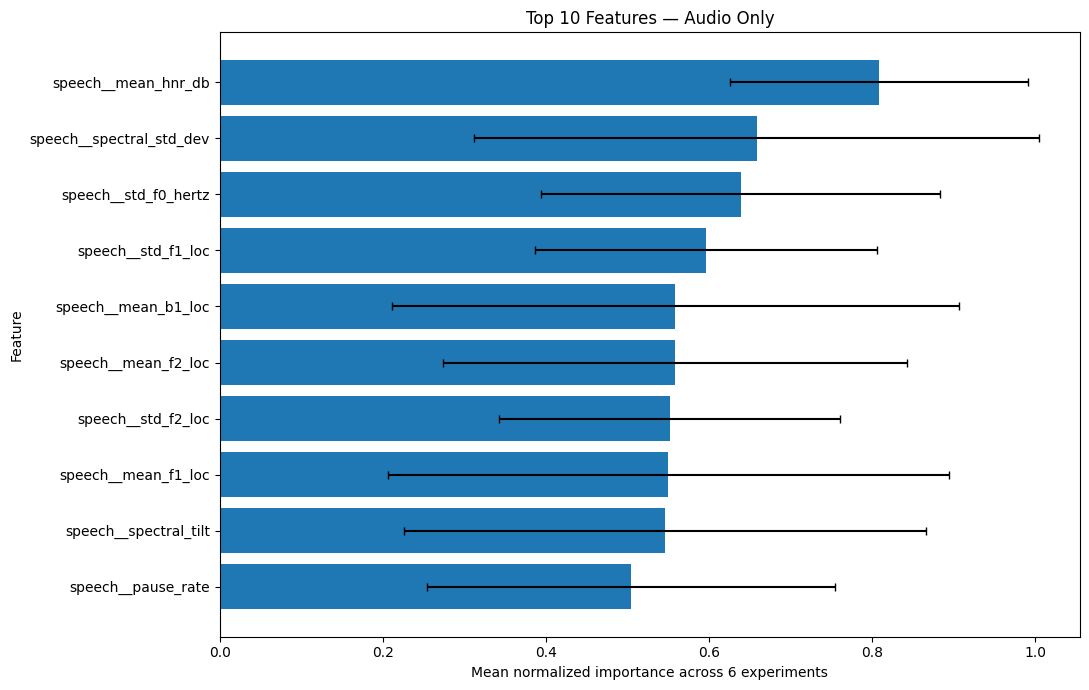

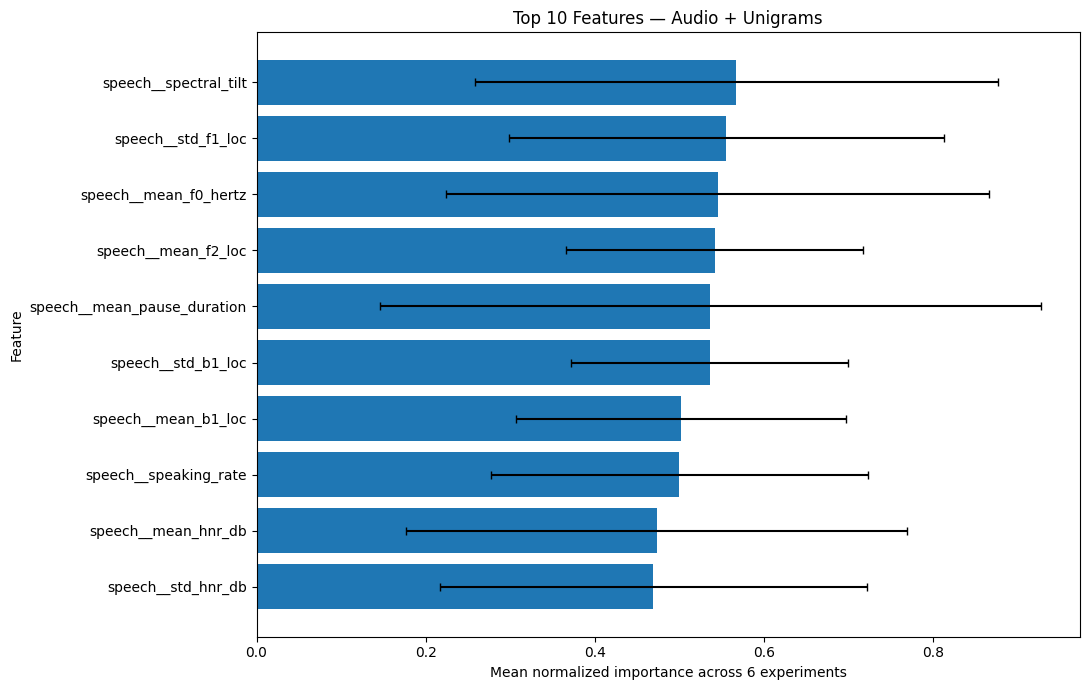

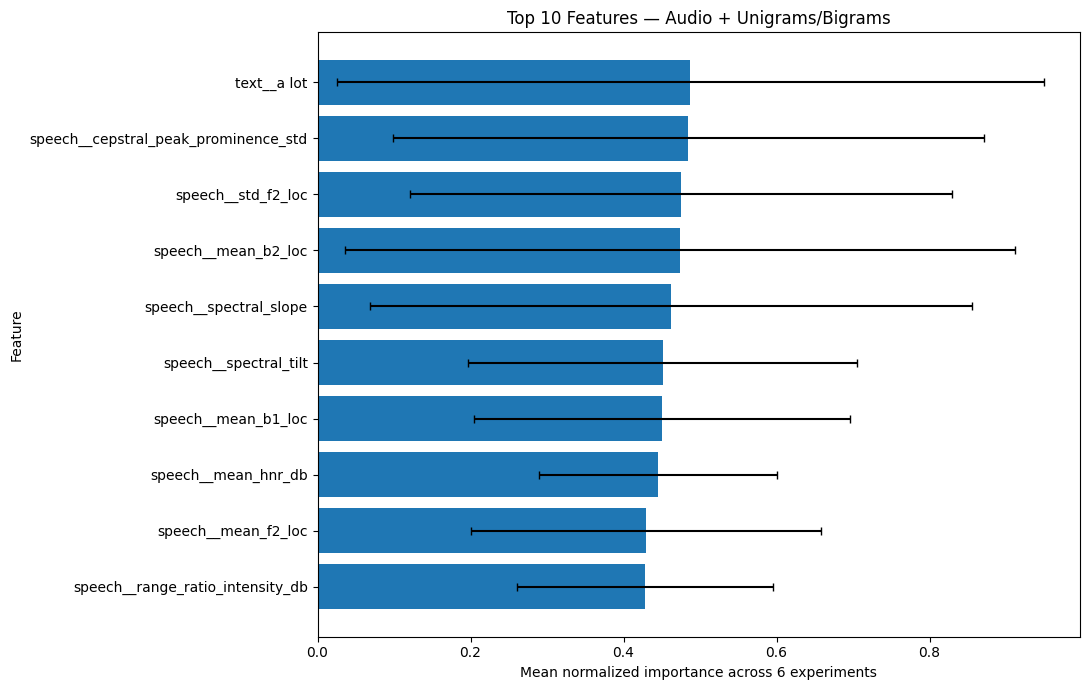

In [27]:
FEATURE_SET_TITLES = {
    "audio_only":
        "Audio Only",

    "audio_unigrams":
        "Audio + Unigrams",

    "audio_unigrams_bigrams":
        "Audio + Unigrams/Bigrams",
}


def plot_top_features(
    feature_set,
    top_n=10,
):

    df = (
        aggregated_results[
            feature_set
        ]
        .head(top_n)
        .sort_values(
            "mean_normalized_importance",
            ascending=True,
        )
    )

    plt.figure(
        figsize=(11, 7)
    )

    plt.barh(
        df["feature"],
        df[
            "mean_normalized_importance"
        ],
        xerr=df[
            "sd_normalized_importance"
        ],
        capsize=3,
    )

    plt.xlabel(
        "Mean normalized importance "
        "across 6 experiments"
    )

    plt.ylabel("Feature")

    plt.title(
        "Top 10 Features — "
        + FEATURE_SET_TITLES[
            feature_set
        ]
    )

    plt.tight_layout()

    output_path = (
        RESULTS_DIR
        / f"{feature_set}_top10_importance.png"
    )

    plt.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()


for feature_set in EXPERIMENTS:
    plot_top_features(
        feature_set
    )

In [28]:
def make_experiment_importance_table(
    feature_set,
):

    top10 = (
        top_features[
            feature_set
        ]["feature"]
        .tolist()
    )

    df = (
        long_results[
            feature_set
        ]
        .loc[
            lambda x:
            x["feature"].isin(
                top10
            )
        ]
    )

    table = (
        df.pivot(
            index="feature",
            columns="experiment",
            values="normalized_importance",
        )
    )

    aggregate_order = (
        top_features[
            feature_set
        ]
        .set_index("feature")[
            "mean_normalized_importance"
        ]
    )

    table[
        "mean_across_6"
    ] = aggregate_order

    table = table.sort_values(
        "mean_across_6",
        ascending=False,
    )

    return table


importance_tables = {}

for feature_set in EXPERIMENTS:

    importance_tables[
        feature_set
    ] = (
        make_experiment_importance_table(
            feature_set
        )
    )

    print("\n", feature_set)

    display(
        importance_tables[
            feature_set
        ]
    )


 audio_only


experiment,dnamite_1,dnamite_2,dnamite_3,nam_v1_1,nam_v1_2,nam_v1_3,mean_across_6
feature,,,,,,,
speech__mean_hnr_db,0.745214,1.000000,0.861514,0.711662,1.000000,0.532104,0.808416
speech__spectral_std_dev,0.248341,0.304513,0.947210,0.505827,0.944775,1.000000,0.658444
speech__std_f0_hertz,0.235043,0.628482,1.000000,0.686373,0.678554,0.604101,0.638759
speech__std_f1_loc,0.573383,0.338495,0.476101,0.750662,0.924951,0.513479,0.596179
speech__mean_b1_loc,1.000000,0.000000,0.530227,0.594050,0.823606,0.402869,0.558458
speech__mean_f2_loc,0.507942,0.096018,0.942714,0.663478,0.451179,0.687812,0.558191
speech__std_f2_loc,0.317545,0.325323,0.573228,0.584191,0.637682,0.872202,0.551696
speech__mean_f1_loc,0.771281,0.000000,0.652854,1.000000,0.433021,0.444188,0.550224
speech__spectral_tilt,0.410801,0.000000,0.695685,0.890578,0.500137,0.778636,0.545973



 audio_unigrams


experiment,dnamite_1,dnamite_2,dnamite_3,nam_v1_1,nam_v1_2,nam_v1_3,mean_across_6
feature,,,,,,,
speech__spectral_tilt,0.297108,0.184113,0.800467,0.649690,0.472145,1.000000,0.567254
speech__std_f1_loc,0.225861,0.619752,0.915018,0.737336,0.324217,0.508642,0.555138
speech__mean_f0_hertz,0.329604,0.056318,0.648972,0.632009,1.000000,0.602349,0.544875
speech__mean_f2_loc,0.295391,0.547727,0.699280,0.436105,0.494440,0.774851,0.541299
speech__mean_pause_duration,0.443025,0.022060,1.000000,1.000000,0.309991,0.442049,0.536187
speech__std_b1_loc,0.373571,0.425527,0.468695,0.461139,0.747285,0.736974,0.535532
speech__mean_b1_loc,0.276077,0.440039,0.741059,0.591400,0.295547,0.665675,0.501633
speech__speaking_rate,0.312512,0.585539,0.844385,0.316319,0.310050,0.629130,0.499656
speech__mean_hnr_db,1.000000,0.343708,0.560755,0.334031,0.129170,0.468836,0.472750



 audio_unigrams_bigrams


experiment,dnamite_1,dnamite_2,dnamite_3,nam_v1_1,nam_v1_2,nam_v1_3,mean_across_6
feature,,,,,,,
text__a lot,1.000000,1.000000,0.678170,0.151456,0.000000,0.093610,0.487206
speech__cepstral_peak_prominence_std,0.126707,0.044372,0.456996,0.405868,0.874853,1.000000,0.484799
speech__std_f2_loc,0.096627,0.110347,0.317909,0.955825,0.751295,0.617640,0.474941
speech__mean_b2_loc,0.040770,0.026302,0.203946,1.000000,0.895623,0.676756,0.473900
speech__spectral_slope,0.070207,0.151846,0.133380,0.663119,1.000000,0.756138,0.462448
speech__spectral_tilt,0.162646,0.287790,0.244792,0.766554,0.701264,0.543079,0.451021
speech__mean_b1_loc,0.113401,0.503143,0.228614,0.556043,0.801635,0.497879,0.450119
speech__mean_hnr_db,0.329118,0.193055,0.515553,0.582198,0.467150,0.586388,0.445577
speech__mean_f2_loc,0.098926,0.325005,0.333645,0.566364,0.492099,0.760537,0.429429


In [29]:
def get_rank_stability(
    feature_set,
):

    top10 = (
        top_features[
            feature_set
        ]["feature"]
        .tolist()
    )

    df = (
        all_feature_importance[
            (
                all_feature_importance[
                    "feature_set"
                ] == feature_set
            )
            &
            (
                all_feature_importance[
                    "feature"
                ].isin(top10)
            )
        ]
        .copy()
    )

    available_columns = [
        col
        for col in [
            "feature",
            "experiment",
            "model",
            "mean_rank",
            "sd_rank",
            "folds_present",
            "top_k_frequency",
        ]
        if col in df.columns
    ]

    return (
        df[available_columns]
        .sort_values(
            [
                "feature",
                "experiment",
            ]
        )
    )


rank_stability = {}

for feature_set in EXPERIMENTS:

    rank_stability[
        feature_set
    ] = (
        get_rank_stability(
            feature_set
        )
    )

    print("\n")
    print(
        FEATURE_SET_TITLES[
            feature_set
        ]
    )

    display(
        rank_stability[
            feature_set
        ]
    )



Audio Only


,feature,experiment,model,mean_rank,sd_rank,folds_present,top_k_frequency
0,speech__mean_b1_loc,dnamite_1,DNAMite,11.400000,9.762172,5,3
65,speech__mean_b1_loc,dnamite_3,DNAMite,14.600000,8.961027,5,1
90,speech__mean_b1_loc,nam_v1_1,NAM v1,18.200000,12.132601,5,2
105,speech__mean_b1_loc,nam_v1_2,NAM v1,6.000000,5.567764,3,2
154,speech__mean_b1_loc,nam_v1_3,NAM v1,19.600000,7.700649,5,1
1,speech__mean_f1_loc,dnamite_1,DNAMite,8.600000,8.018728,5,4
57,speech__mean_f1_loc,dnamite_3,DNAMite,11.000000,7.382412,5,2
74,speech__mean_f1_loc,nam_v1_1,NAM v1,6.800000,4.494441,5,4
123,speech__mean_f1_loc,nam_v1_2,NAM v1,12.000000,NaN,1,0
152,speech__mean_f1_loc,nam_v1_3,NAM v1,17.400000,6.985700,5,1




Audio + Unigrams


,feature,experiment,model,mean_rank,sd_rank,folds_present,top_k_frequency
174,speech__mean_b1_loc,dnamite_1,DNAMite,9.200000,4.919350,5,5
197,speech__mean_b1_loc,dnamite_2,DNAMite,7.500000,0.707107,2,2
235,speech__mean_b1_loc,dnamite_3,DNAMite,11.000000,7.905694,5,5
268,speech__mean_b1_loc,nam_v1_1,NAM v1,11.600000,6.066300,5,3
308,speech__mean_b1_loc,nam_v1_2,NAM v1,9.333333,8.386497,3,2
331,speech__mean_b1_loc,nam_v1_3,NAM v1,12.400000,8.354639,5,2
163,speech__mean_f0_hertz,dnamite_1,DNAMite,13.800000,12.235195,5,4
218,speech__mean_f0_hertz,dnamite_2,DNAMite,7.000000,NaN,1,1
241,speech__mean_f0_hertz,dnamite_3,DNAMite,17.800000,10.281051,5,5
266,speech__mean_f0_hertz,nam_v1_1,NAM v1,12.000000,10.295630,5,2




Audio + Unigrams/Bigrams


,feature,experiment,model,mean_rank,sd_rank,folds_present,top_k_frequency
399,speech__cepstral_peak_prominence_std,dnamite_1,DNAMite,24.400000,15.175638,5,3
495,speech__cepstral_peak_prominence_std,dnamite_2,DNAMite,35.000000,NaN,1,0
524,speech__cepstral_peak_prominence_std,dnamite_3,DNAMite,12.200000,17.123084,5,4
611,speech__cepstral_peak_prominence_std,nam_v1_1,NAM v1,18.800000,3.114482,5,0
678,speech__cepstral_peak_prominence_std,nam_v1_2,NAM v1,5.800000,5.263079,5,4
702,speech__cepstral_peak_prominence_std,nam_v1_3,NAM v1,7.600000,4.560702,5,3
405,speech__mean_b1_loc,dnamite_1,DNAMite,24.400000,10.237187,5,3
451,speech__mean_b1_loc,dnamite_2,DNAMite,11.000000,14.142136,2,2
559,speech__mean_b1_loc,dnamite_3,DNAMite,26.600000,8.018728,5,3
603,speech__mean_b1_loc,nam_v1_1,NAM v1,14.000000,7.211103,5,2


In [30]:
def summarize_rank_stability(
    feature_set,
):

    df = rank_stability[
        feature_set
    ].copy()

    agg_dict = {}

    if "mean_rank" in df.columns:
        agg_dict[
            "mean_rank_across_experiments"
        ] = (
            "mean_rank",
            "mean",
        )

        agg_dict[
            "sd_of_mean_rank"
        ] = (
            "mean_rank",
            "std",
        )

    if "sd_rank" in df.columns:
        agg_dict[
            "mean_within_experiment_rank_sd"
        ] = (
            "sd_rank",
            "mean",
        )

    if "top_k_frequency" in df.columns:
        agg_dict[
            "mean_top_k_frequency"
        ] = (
            "top_k_frequency",
            "mean",
        )

        agg_dict[
            "total_top_k_occurrences"
        ] = (
            "top_k_frequency",
            "sum",
        )

    if "folds_present" in df.columns:
        agg_dict[
            "mean_folds_present"
        ] = (
            "folds_present",
            "mean",
        )

    summary = (
        df
        .groupby(
            "feature",
            as_index=False,
        )
        .agg(**agg_dict)
    )

    importance_order = (
        top_features[
            feature_set
        ][
            [
                "feature",
                "aggregate_rank",
                "mean_normalized_importance",
                "experiments_present",
            ]
        ]
    )

    summary = (
        importance_order
        .merge(
            summary,
            on="feature",
            how="left",
        )
        .sort_values(
            "aggregate_rank"
        )
    )

    return summary


rank_summary = {}

for feature_set in EXPERIMENTS:

    rank_summary[
        feature_set
    ] = (
        summarize_rank_stability(
            feature_set
        )
    )

    print("\n")
    print(
        FEATURE_SET_TITLES[
            feature_set
        ]
    )

    display(
        rank_summary[
            feature_set
        ]
    )



Audio Only


,feature,aggregate_rank,mean_normalized_importance,experiments_present,mean_rank_across_experiments,sd_of_mean_rank,mean_within_experiment_rank_sd,mean_top_k_frequency,total_top_k_occurrences,mean_folds_present
0,speech__mean_hnr_db,1,0.808416,6,8.250000,5.856193,5.387556,2.666667,16,4.000000
1,speech__spectral_std_dev,2,0.658444,6,10.166667,6.345287,7.757578,2.333333,14,4.000000
2,speech__std_f0_hertz,3,0.638759,6,10.583333,4.943042,5.559109,2.500000,15,4.666667
3,speech__std_f1_loc,4,0.596179,6,11.933333,5.963444,7.399297,2.333333,14,5.000000
4,speech__mean_b1_loc,5,0.558458,5,13.960000,5.479781,8.824843,1.800000,9,4.600000
5,speech__mean_f2_loc,6,0.558191,6,10.766667,3.701951,7.375470,2.000000,12,4.333333
6,speech__std_f2_loc,7,0.551696,6,11.600000,5.738292,7.578137,2.166667,13,4.333333
7,speech__mean_f1_loc,8,0.550224,5,11.160000,4.038316,6.720320,2.200000,11,4.200000
8,speech__spectral_tilt,9,0.545973,5,10.720000,3.192491,5.647237,2.400000,12,4.800000
9,speech__pause_rate,10,0.504343,6,10.425000,3.619910,6.348584,2.666667,16,4.666667




Audio + Unigrams


,feature,aggregate_rank,mean_normalized_importance,experiments_present,mean_rank_across_experiments,sd_of_mean_rank,mean_within_experiment_rank_sd,mean_top_k_frequency,total_top_k_occurrences,mean_folds_present
0,speech__spectral_tilt,1,0.567254,6,10.844444,4.482394,7.804004,4.000000,24,4.500000
1,speech__std_f1_loc,2,0.555138,6,11.566667,4.975808,8.080154,3.333333,20,4.666667
2,speech__mean_f0_hertz,3,0.544875,6,11.366667,6.350328,10.681628,2.333333,14,3.666667
3,speech__mean_f2_loc,4,0.541299,6,10.666667,3.708728,6.840236,3.333333,20,4.333333
4,speech__mean_pause_duration,5,0.536187,6,12.733333,7.480820,6.583018,2.833333,17,3.666667
5,speech__std_b1_loc,6,0.535532,6,12.683333,6.684435,8.325418,2.833333,17,3.833333
6,speech__mean_b1_loc,7,0.501633,6,10.172222,1.815295,6.056598,3.166667,19,4.166667
7,speech__speaking_rate,8,0.499656,6,12.483333,6.991543,5.744437,2.500000,15,3.833333
8,speech__mean_hnr_db,9,0.472750,6,15.333333,4.133118,7.482681,2.166667,13,4.000000
9,speech__std_hnr_db,10,0.468893,6,10.150000,4.183659,7.069011,3.333333,20,4.333333




Audio + Unigrams/Bigrams


,feature,aggregate_rank,mean_normalized_importance,experiments_present,mean_rank_across_experiments,sd_of_mean_rank,mean_within_experiment_rank_sd,mean_top_k_frequency,total_top_k_occurrences,mean_folds_present
0,text__a lot,1,0.487206,5,17.533333,15.410314,9.229167,1.400000,7,2.600000
1,speech__cepstral_peak_prominence_std,2,0.484799,6,17.300000,11.120252,9.047397,2.333333,14,4.333333
2,speech__std_f2_loc,3,0.474941,6,15.983333,8.247767,7.039001,2.833333,17,4.166667
3,speech__mean_b2_loc,4,0.473900,6,18.441667,11.901698,7.696585,2.166667,13,4.166667
4,speech__spectral_slope,5,0.462448,6,20.366667,12.433289,6.840713,1.833333,11,4.000000
5,speech__spectral_tilt,6,0.451021,6,14.941667,8.779887,6.289685,3.000000,18,4.333333
6,speech__mean_b1_loc,7,0.450119,6,16.333333,8.163986,8.447312,2.500000,15,4.166667
7,speech__mean_hnr_db,8,0.445577,6,10.877778,4.268212,6.576684,3.000000,18,4.166667
8,speech__mean_f2_loc,9,0.429429,6,16.705556,6.993534,8.356184,3.166667,19,4.166667
9,speech__range_ratio_intensity_db,10,0.428074,6,17.408333,5.441729,10.495227,1.833333,11,4.166667


In [31]:
for feature_set in EXPERIMENTS:

    top_features[
        feature_set
    ].to_csv(
        RESULTS_DIR
        / f"{feature_set}_top10_features.csv",
        index=False,
    )

    importance_tables[
        feature_set
    ].to_csv(
        RESULTS_DIR
        / f"{feature_set}_top10_by_experiment.csv"
    )

    rank_summary[
        feature_set
    ].to_csv(
        RESULTS_DIR
        / f"{feature_set}_top10_rank_stability.csv",
        index=False,
    )

In [32]:
def find_file_recursive(
    experiment_path,
    filename,
):

    experiment_path = Path(
        experiment_path
    )

    matches = list(
        experiment_path.rglob(
            filename
        )
    )

    if len(matches) == 0:
        return None

    if len(matches) > 1:
        print(
            f"Warning: found multiple "
            f"{filename} files under "
            f"{experiment_path}"
        )

    return matches[0]

In [33]:
def load_nam_shape_curves(
    feature_set,
):

    dfs = []

    for experiment_name, relative_path in (
        EXPERIMENTS[
            feature_set
        ].items()
    ):

        if not experiment_name.startswith(
            "nam_v1"
        ):
            continue

        full_path = (
            ROOT
            / relative_path
        )

        file_path = find_file_recursive(
            full_path,
            "shape_function_mean_sd_curves.csv",
        )

        if file_path is None:

            print(
                "Missing shape curves:",
                experiment_name,
            )

            continue

        df = pd.read_csv(
            file_path
        )

        df["experiment"] = (
            experiment_name
        )

        df["feature_set"] = (
            feature_set
        )

        dfs.append(df)

    if not dfs:
        return pd.DataFrame()

    return pd.concat(
        dfs,
        ignore_index=True,
    )

In [34]:
nam_shape_curves = {}

for feature_set in EXPERIMENTS:

    nam_shape_curves[
        feature_set
    ] = (
        load_nam_shape_curves(
            feature_set
        )
    )

    print(
        feature_set,
        nam_shape_curves[
            feature_set
        ].shape,
    )

audio_only (7676, 7)
audio_unigrams (8080, 7)
audio_unigrams_bigrams (11312, 7)


In [35]:
def plot_nam_shape(
    feature_set,
    feature,
):

    df = (
        nam_shape_curves[
            feature_set
        ]
        .loc[
            lambda x:
            x["feature"] == feature
        ]
        .copy()
    )

    if df.empty:
        print(
            f"No NAM shape data for: "
            f"{feature}"
        )
        return

    plt.figure(
        figsize=(10, 6)
    )

    for experiment_name, exp_df in (
        df.groupby("experiment")
    ):

        exp_df = (
            exp_df
            .sort_values(
                "feature_value"
            )
        )

        x = (
            exp_df[
                "feature_value"
            ].to_numpy()
        )

        y = (
            exp_df[
                "mean_centered_contribution"
            ].to_numpy()
        )

        sd = (
            exp_df[
                "sd_centered_contribution"
            ]
            .fillna(0)
            .to_numpy()
        )

        line = plt.plot(
            x,
            y,
            label=experiment_name,
        )[0]

        plt.fill_between(
            x,
            y - sd,
            y + sd,
            alpha=0.15,
            color=line.get_color(),
        )

    plt.axhline(
        0,
        linewidth=1,
        linestyle="--",
    )

    plt.xlabel(
        "Feature value"
    )

    plt.ylabel(
        "Centered NAM contribution"
    )

    plt.title(
        f"NAM v1 Shape Function\n"
        f"{feature}"
    )

    plt.legend()

    plt.tight_layout()

    safe_feature = (
        feature
        .replace("/", "_")
        .replace(" ", "_")
    )

    output_path = (
        RESULTS_DIR
        / (
            f"{feature_set}_"
            f"{safe_feature}_"
            f"nam_shape.png"
        )
    )

    plt.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()



Audio Only


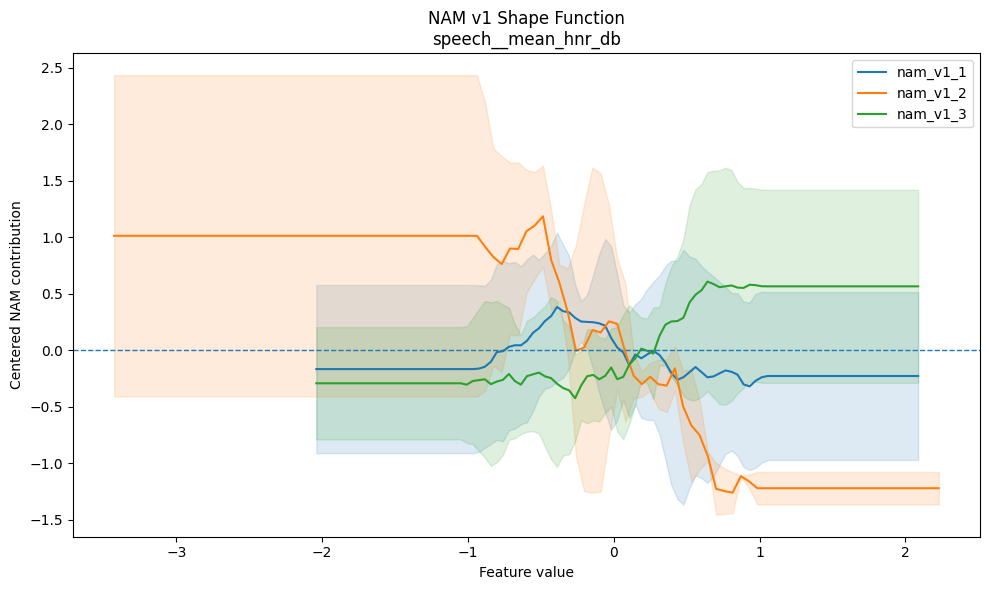

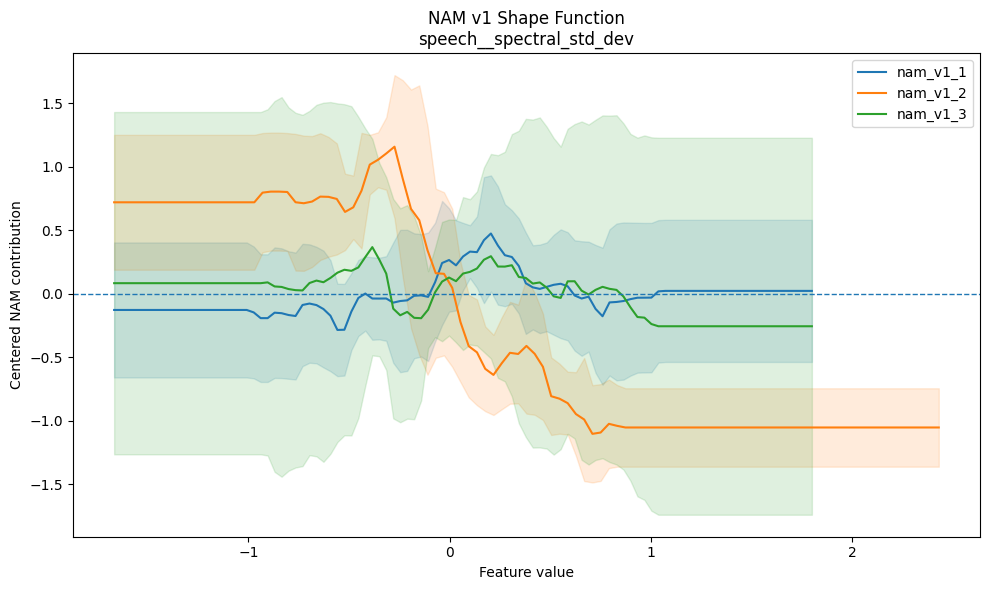

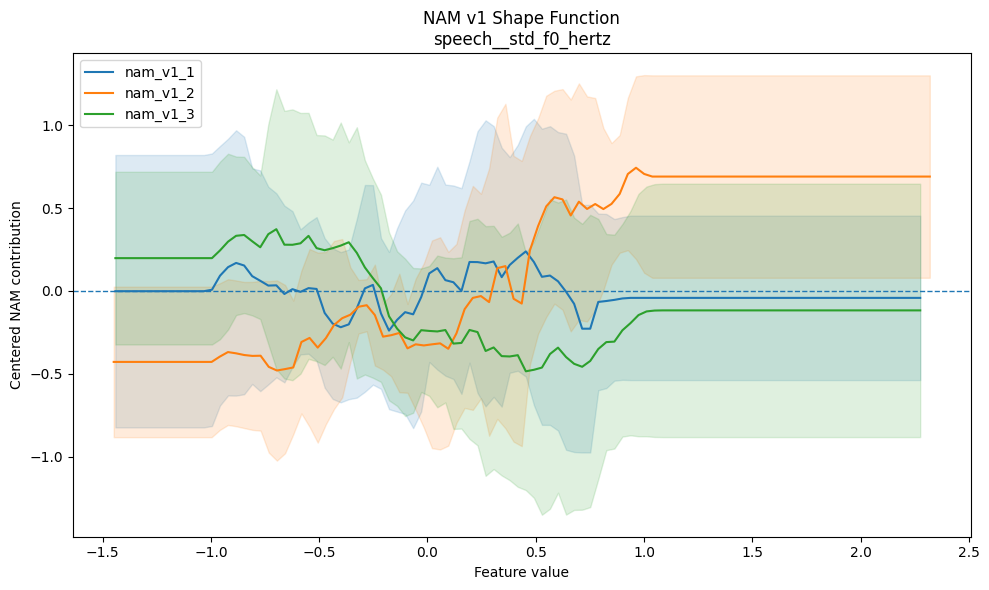

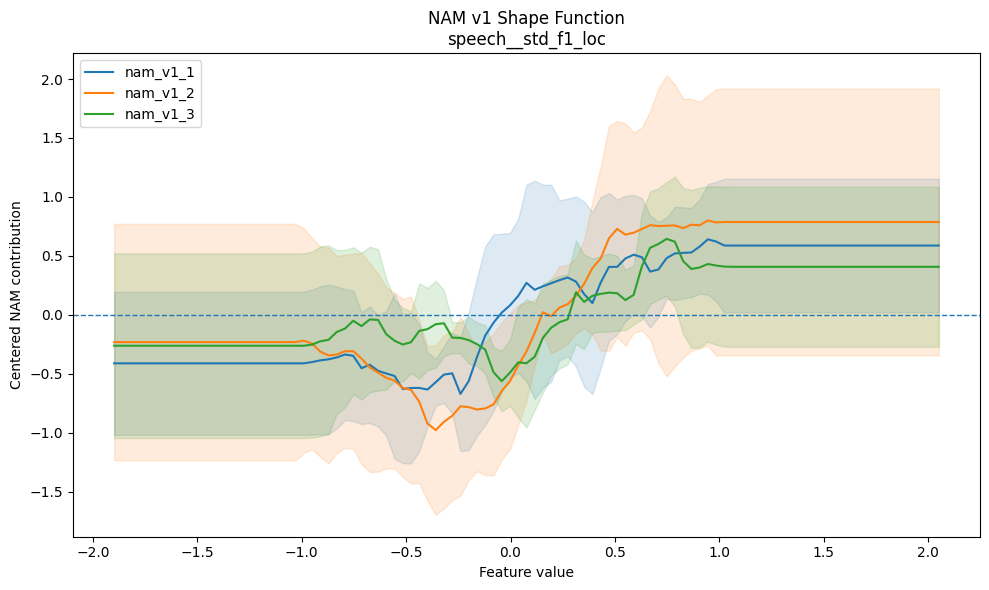

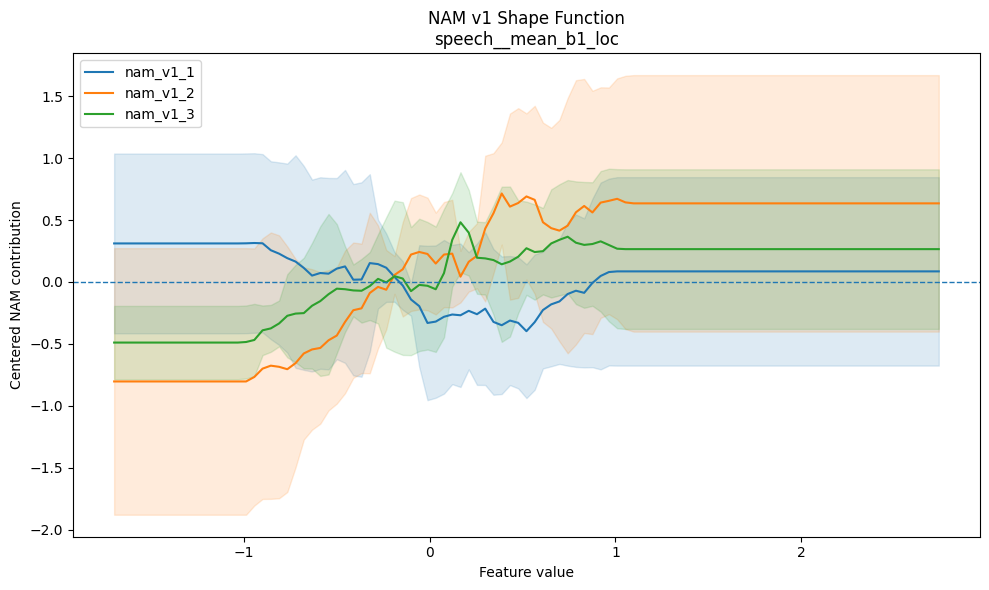

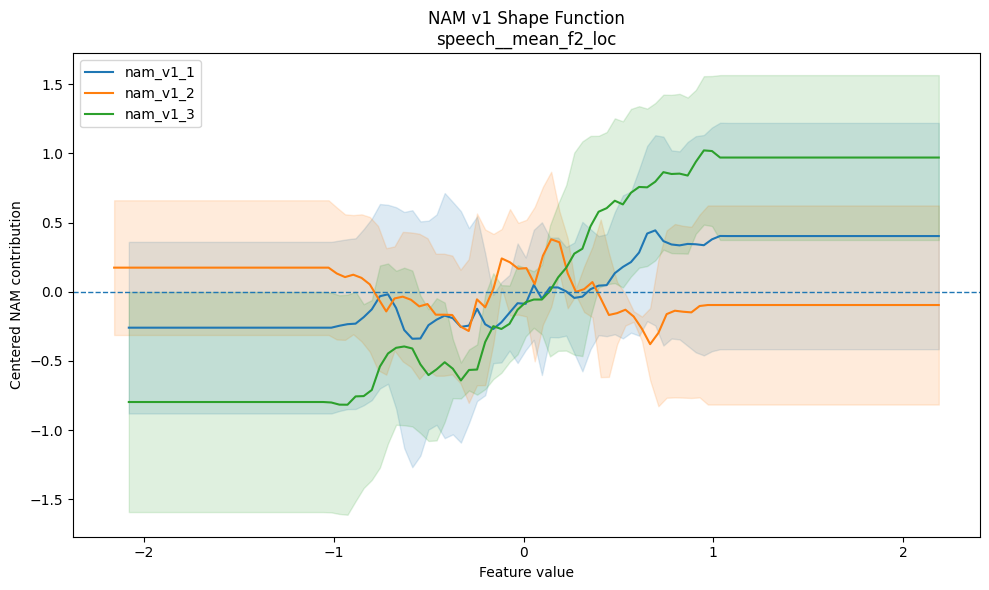

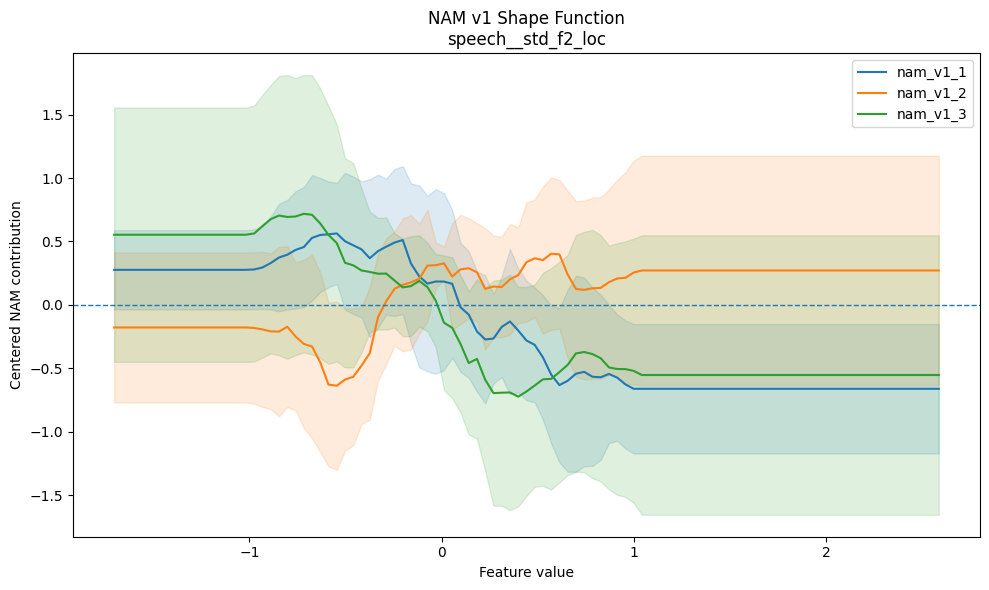

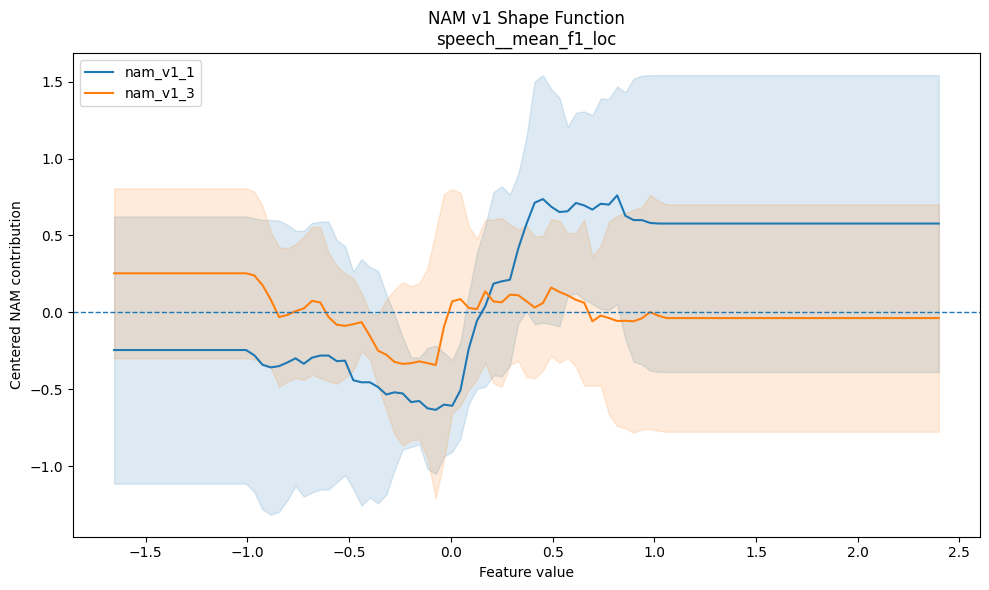

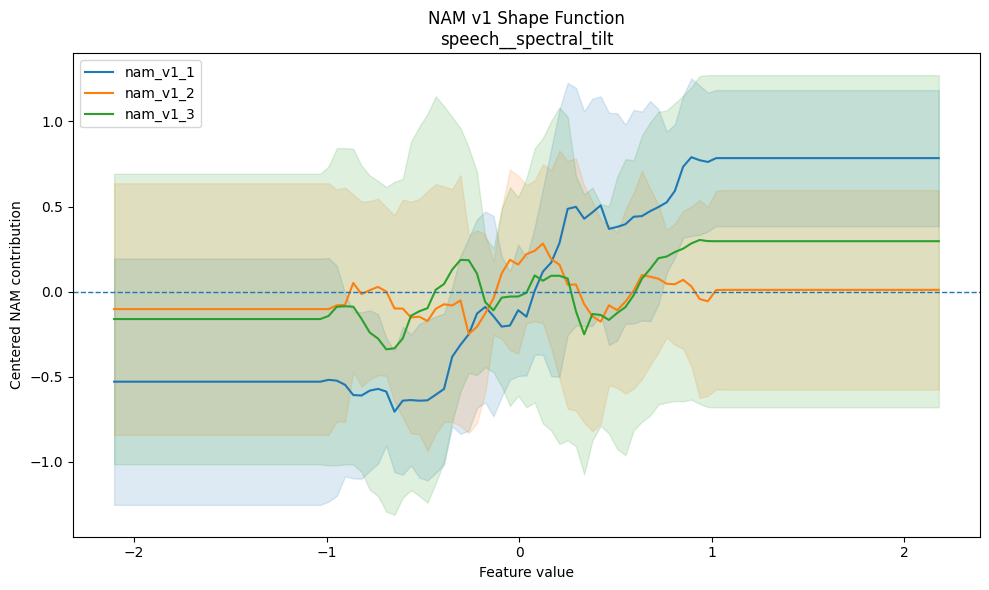

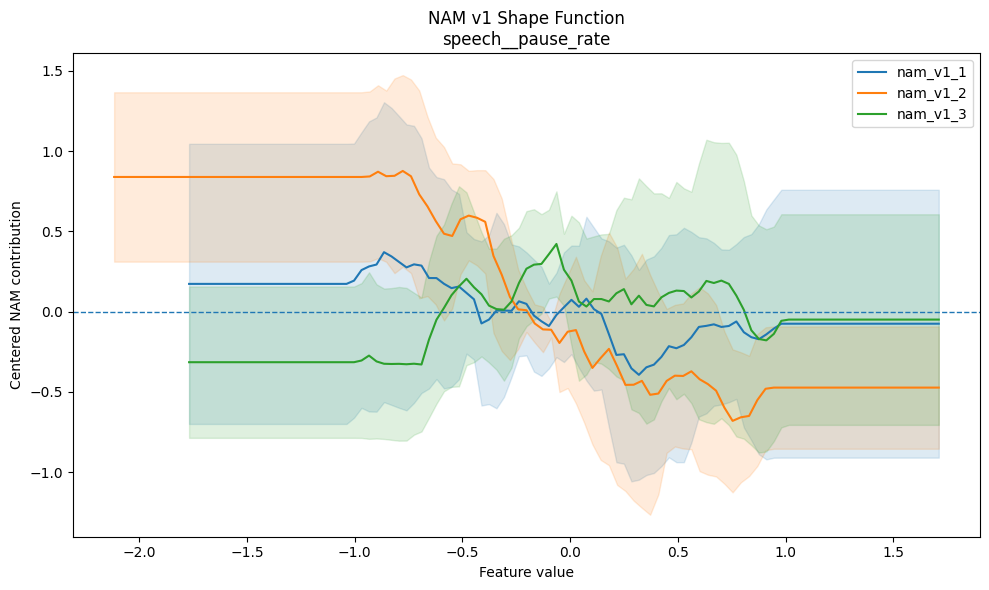



Audio + Unigrams


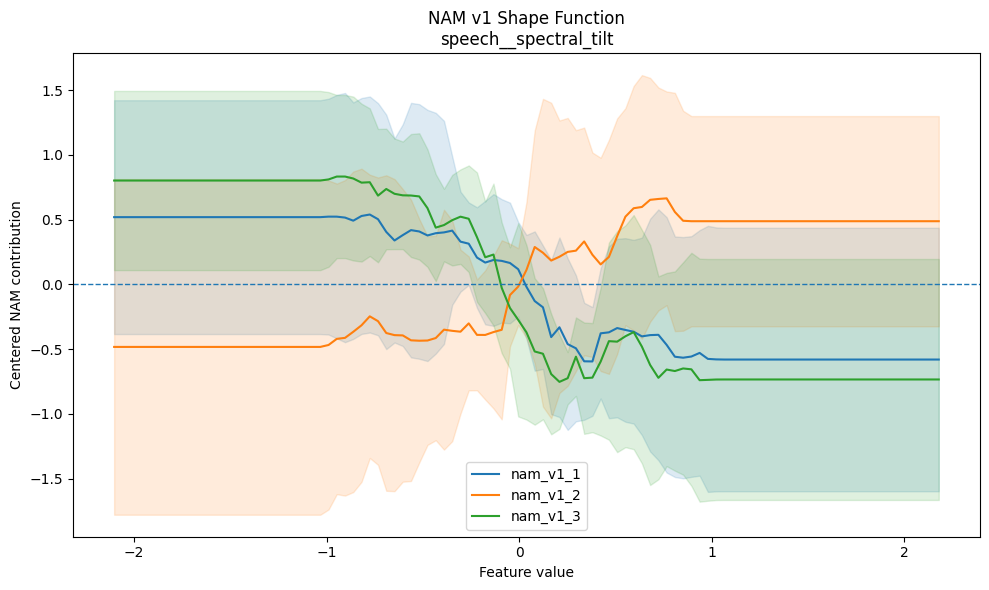

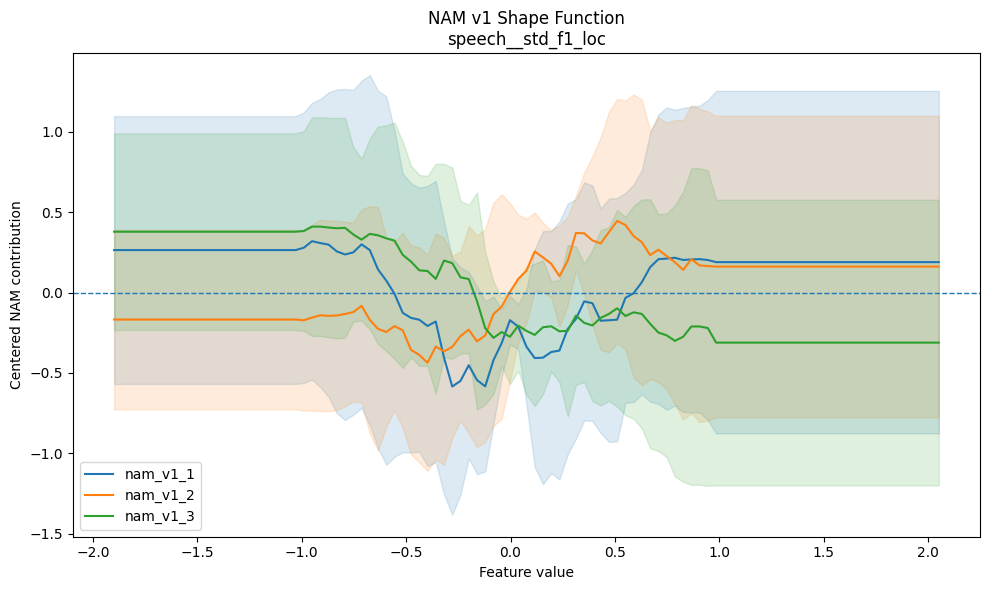

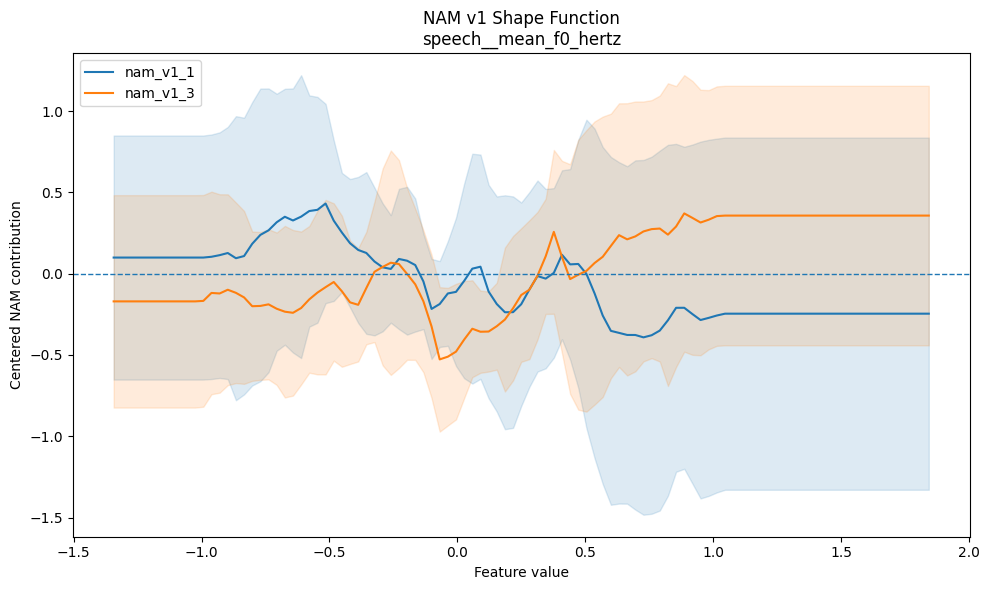

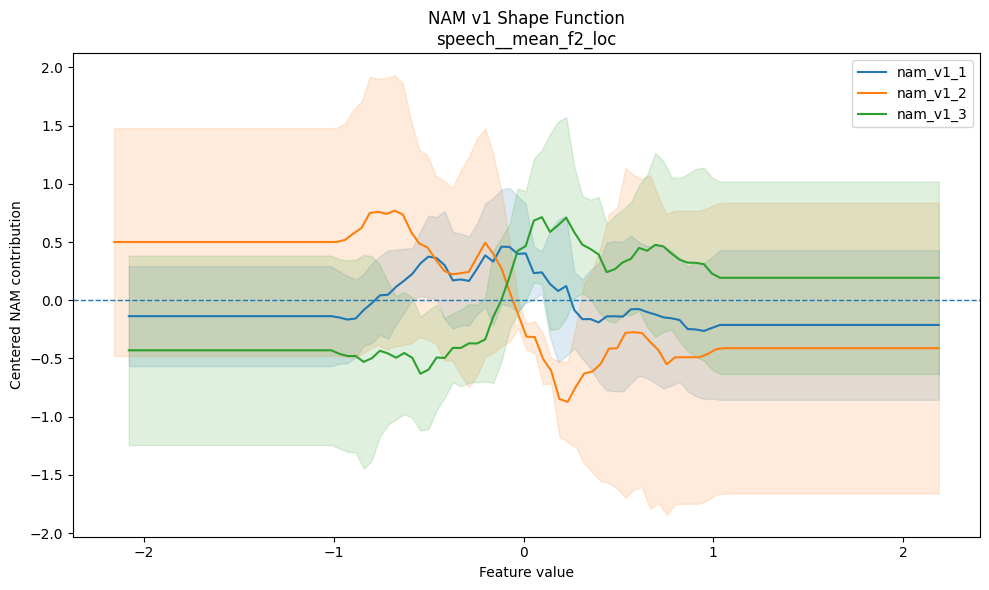

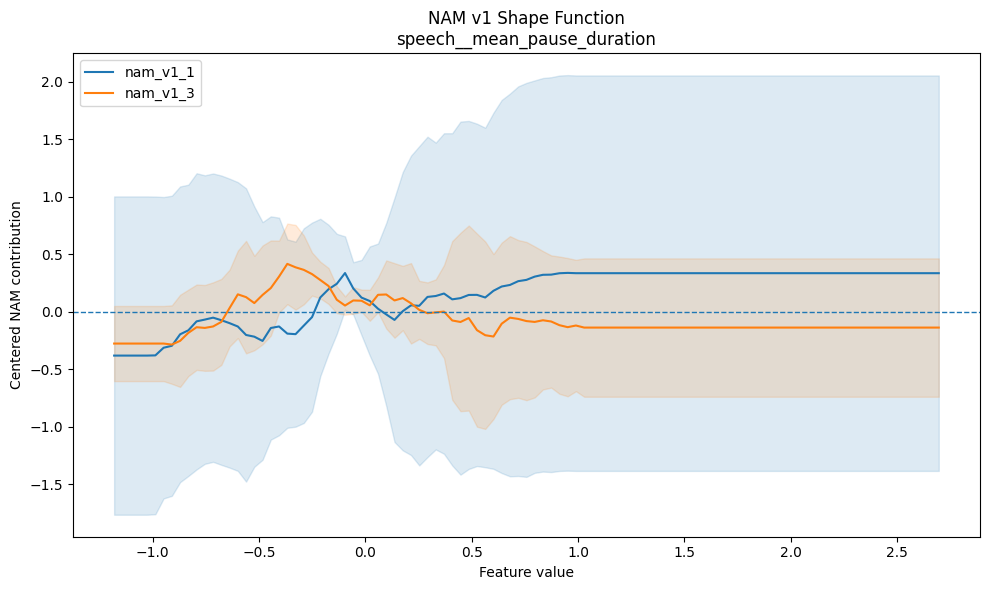

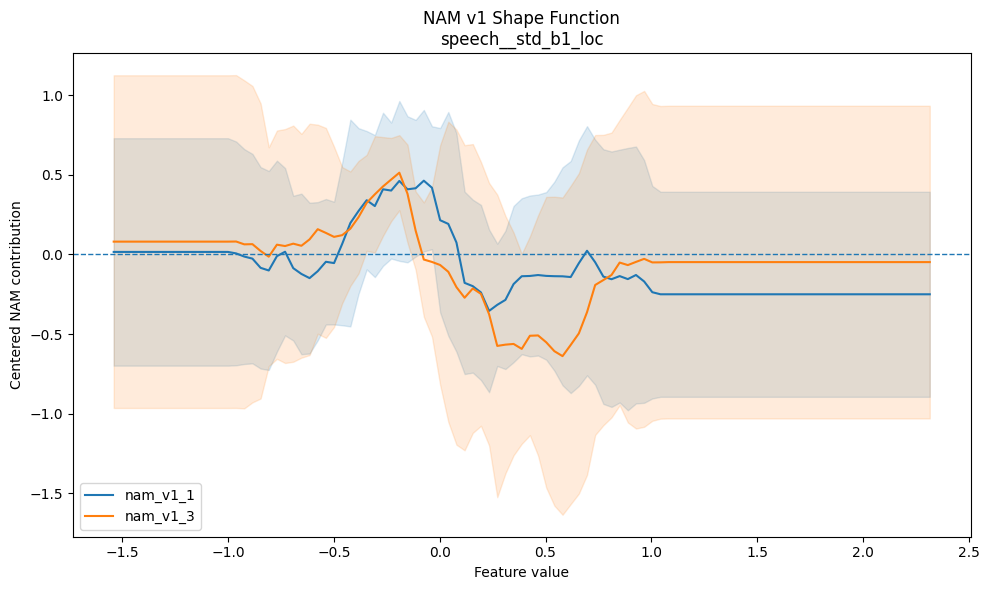

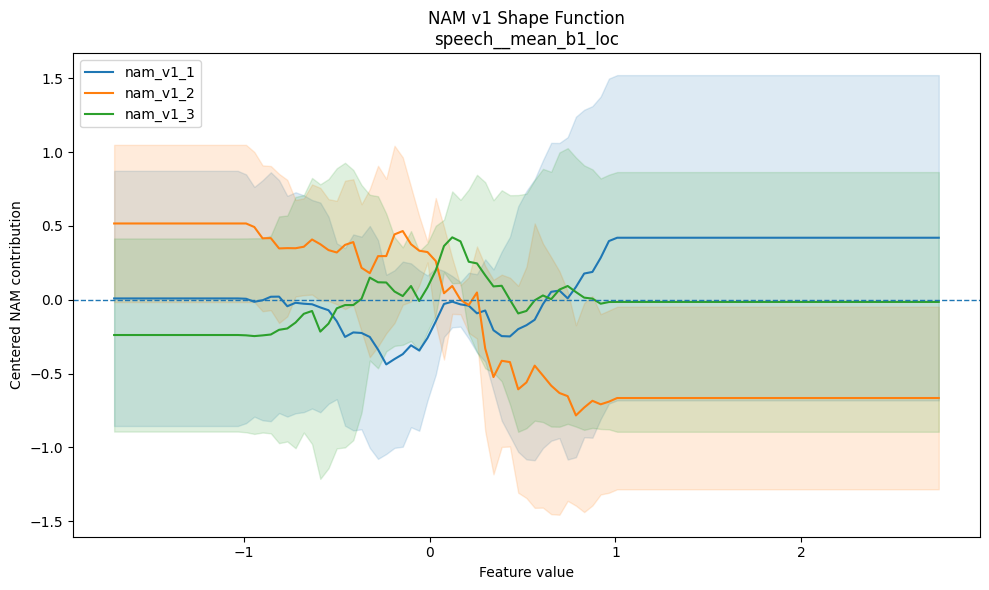

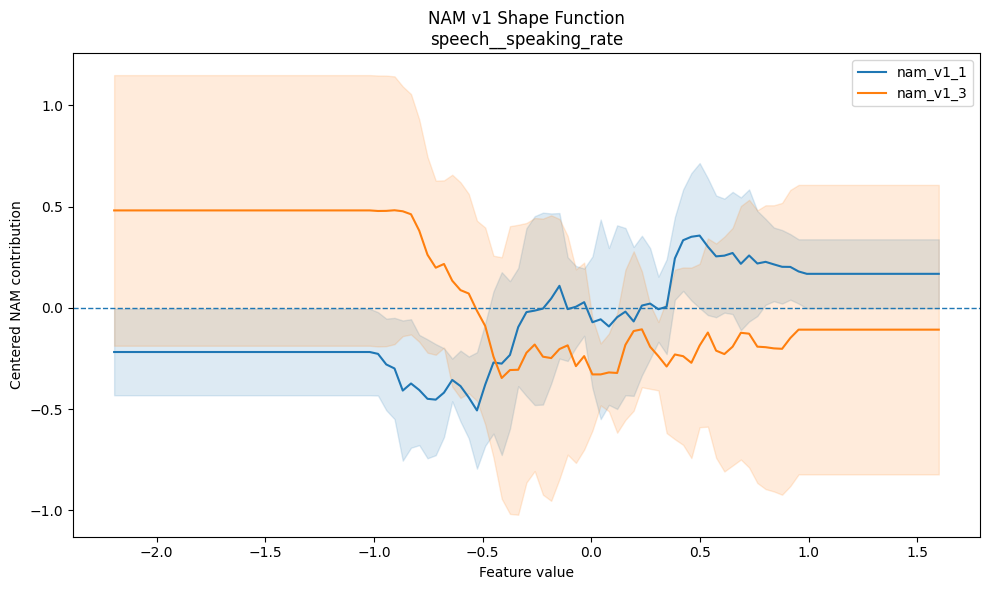

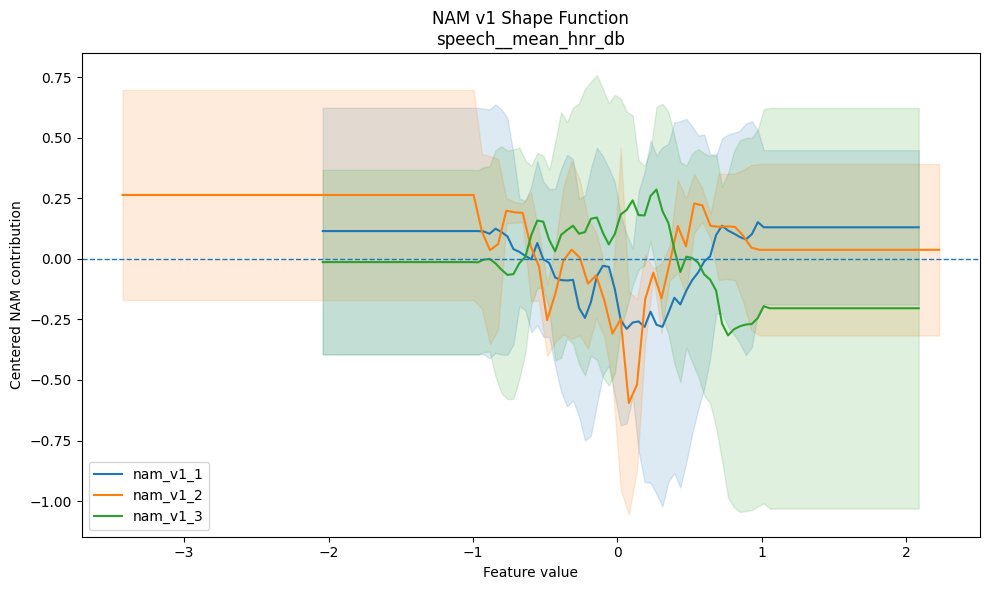

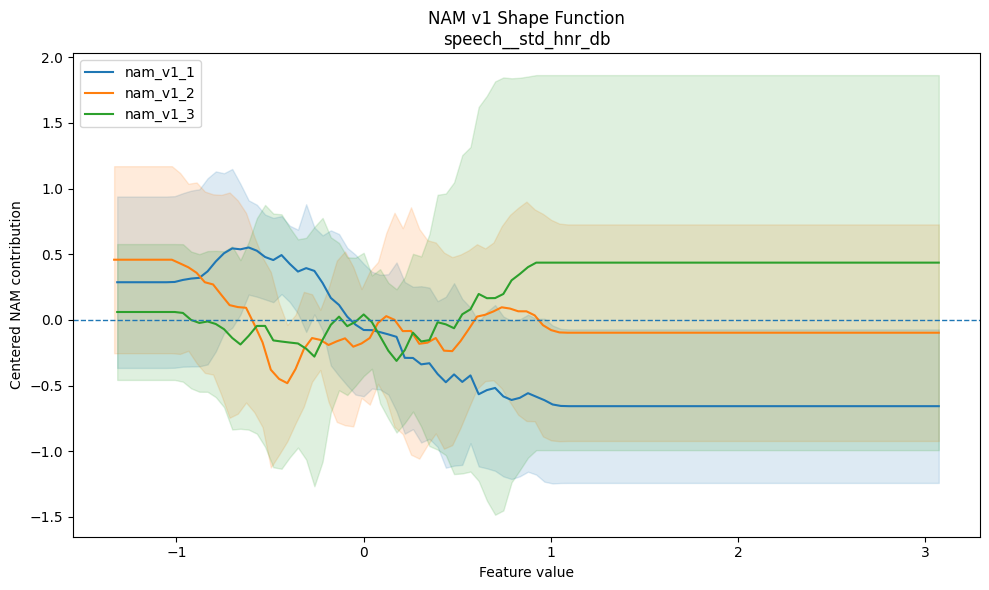



Audio + Unigrams/Bigrams


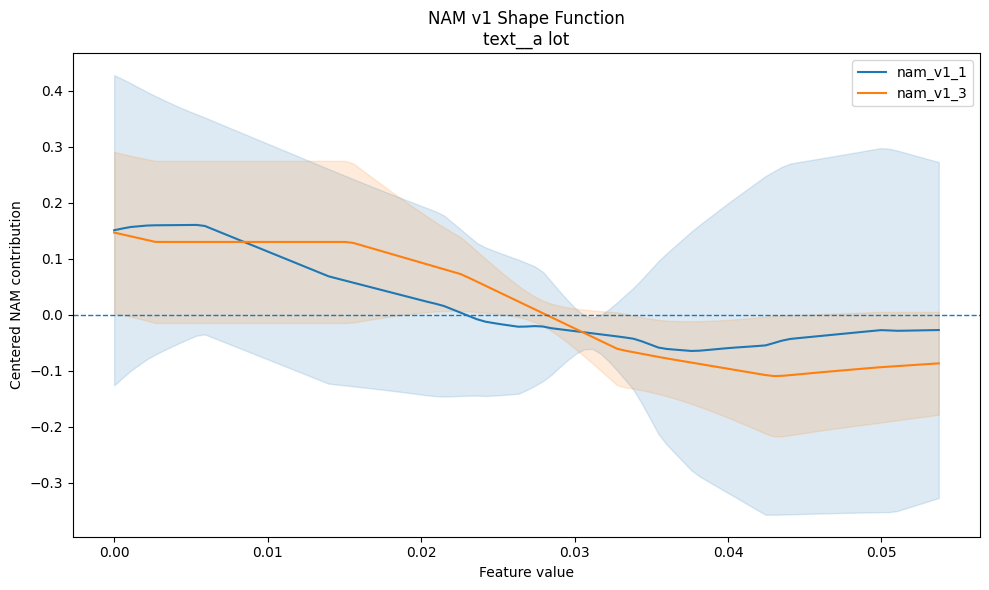

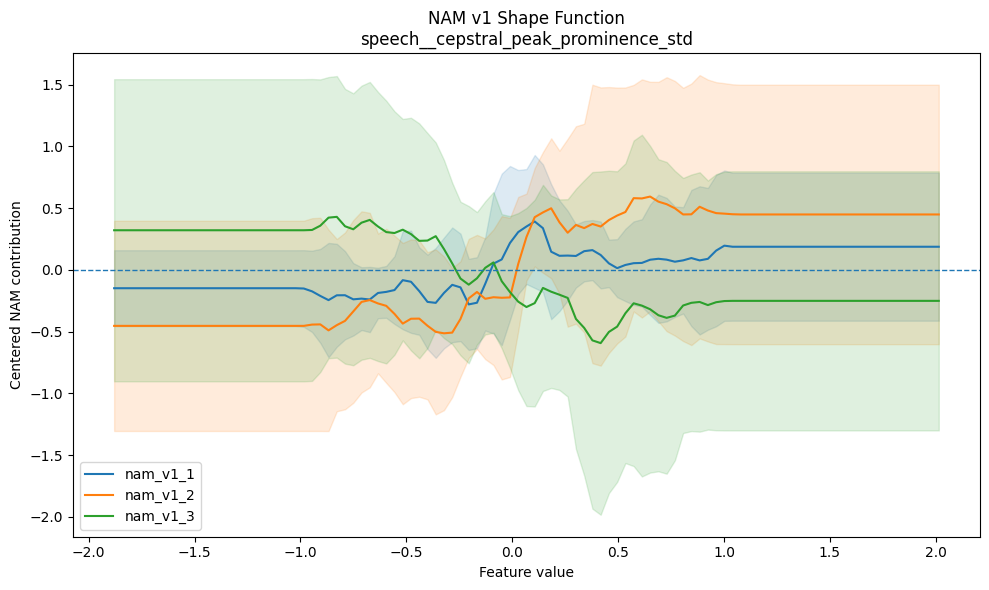

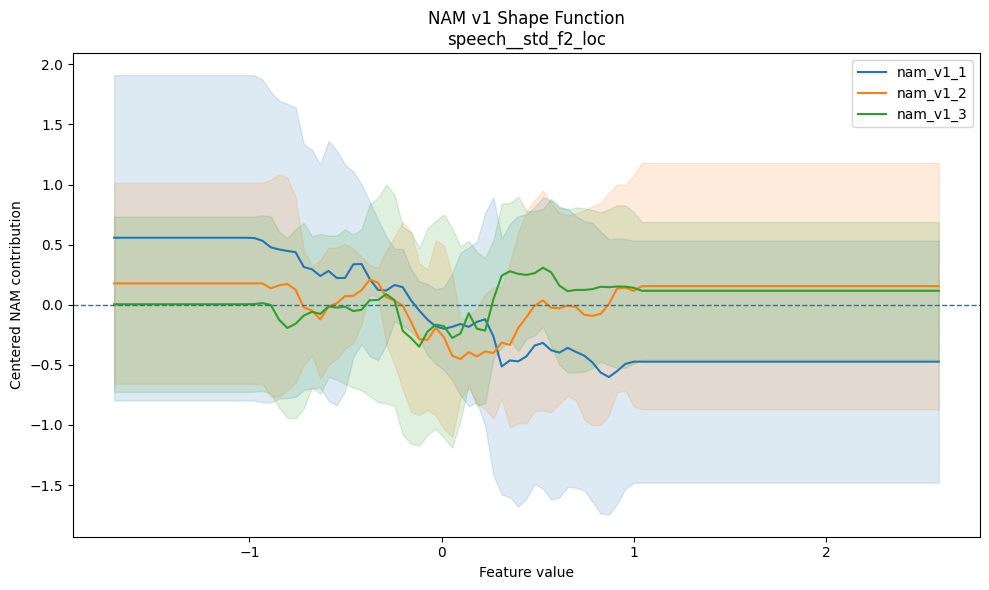

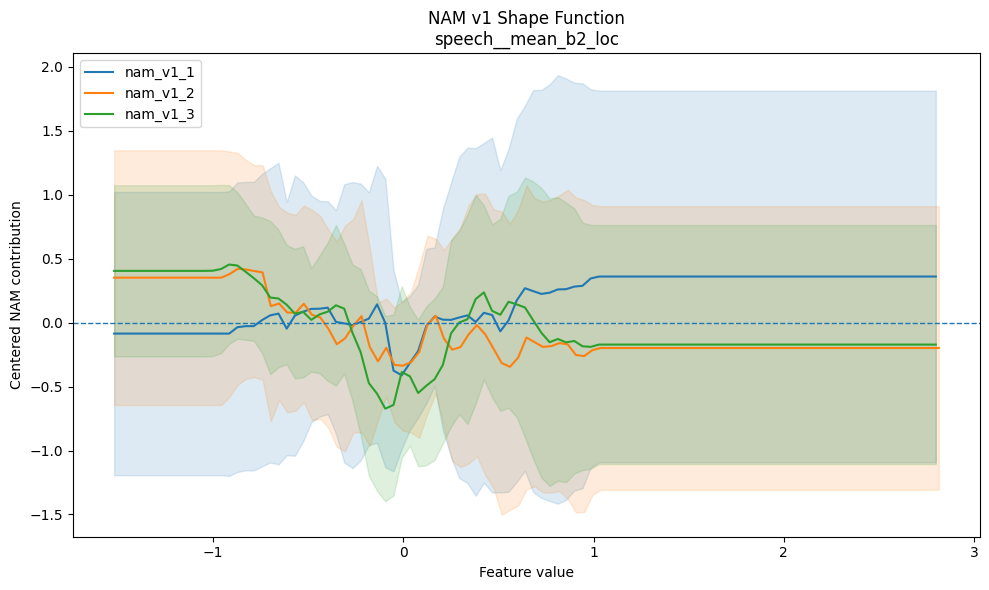

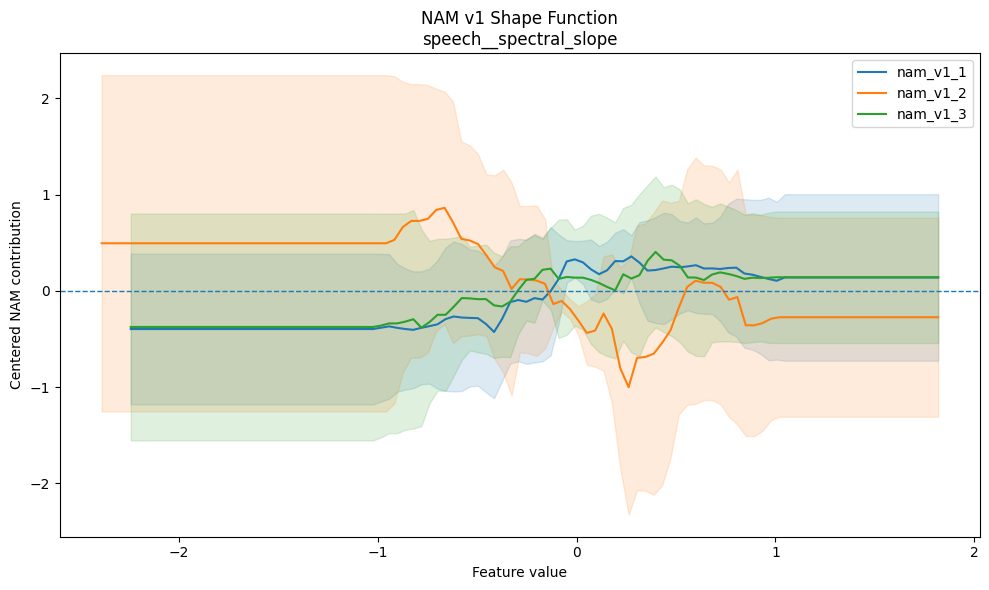

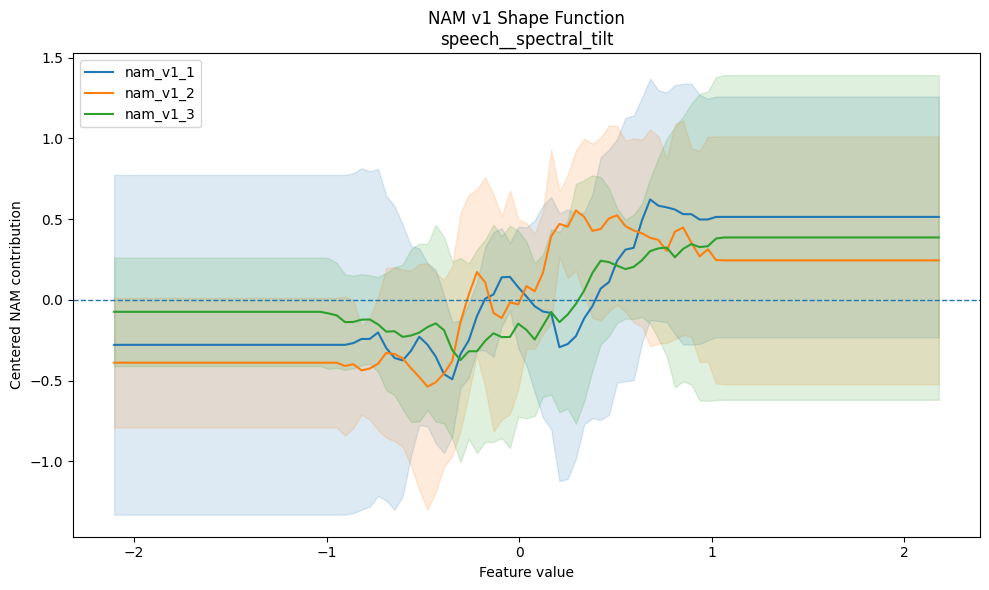

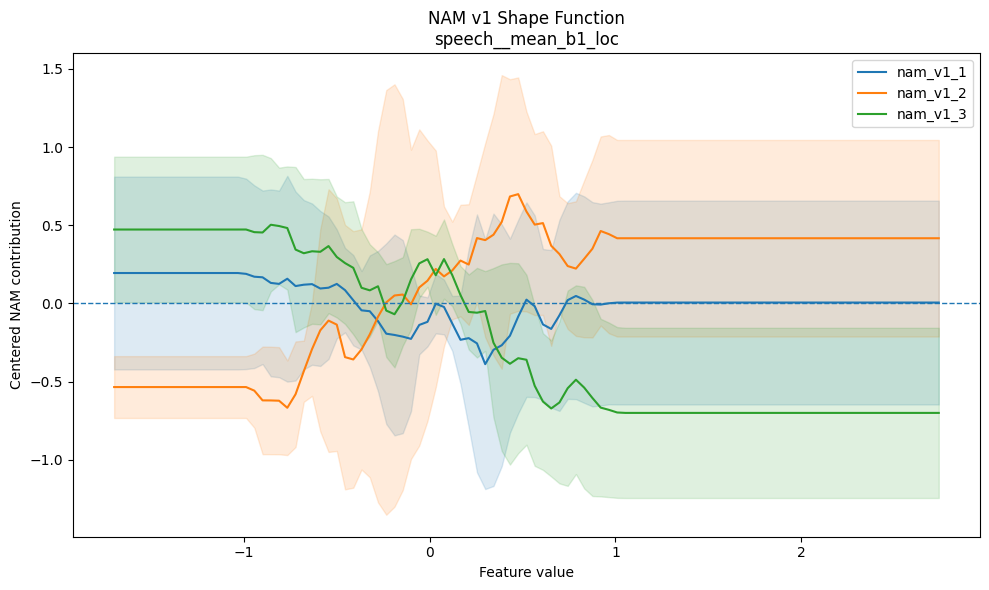

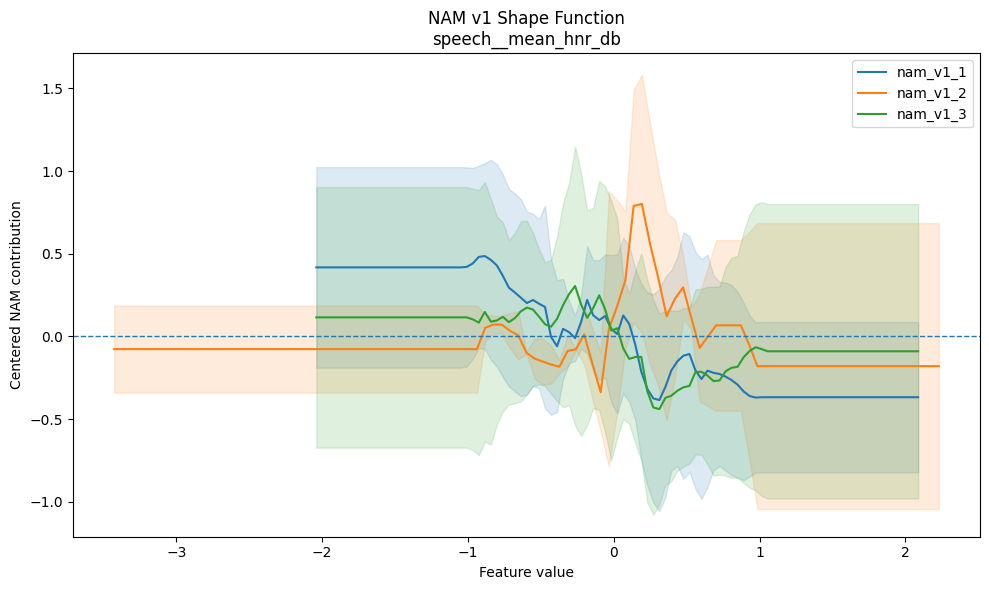

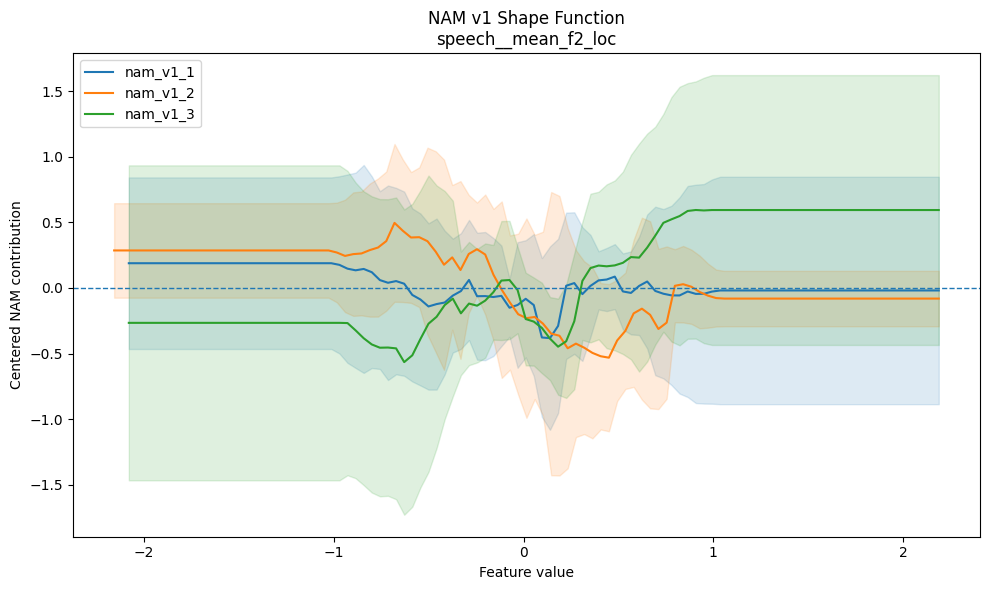

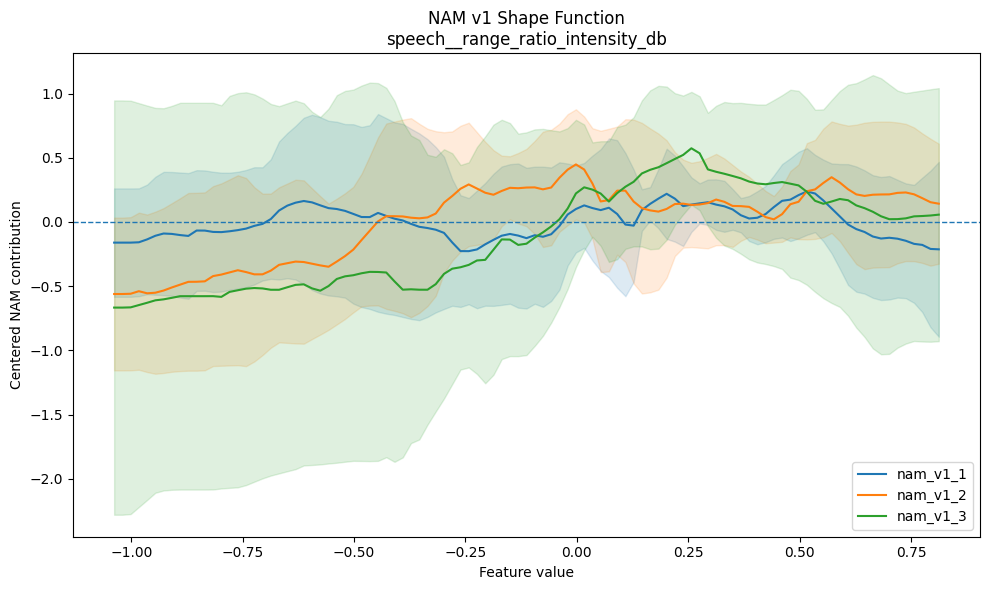

In [36]:
for feature_set in EXPERIMENTS:

    print("\n")
    print("=" * 80)
    print(
        FEATURE_SET_TITLES[
            feature_set
        ]
    )
    print("=" * 80)

    features = (
        top_features[
            feature_set
        ]["feature"]
        .tolist()
    )

    for feature in features:

        plot_nam_shape(
            feature_set,
            feature,
        )

In [37]:
def load_nam_shape_stability(
    feature_set,
):

    dfs = []

    for experiment_name, relative_path in (
        EXPERIMENTS[
            feature_set
        ].items()
    ):

        if not experiment_name.startswith(
            "nam_v1"
        ):
            continue

        full_path = (
            ROOT
            / relative_path
        )

        file_path = find_file_recursive(
            full_path,
            "shape_function_stability.csv",
        )

        if file_path is None:

            print(
                "Missing shape stability:",
                experiment_name,
            )

            continue

        df = pd.read_csv(
            file_path
        )

        df["experiment"] = (
            experiment_name
        )

        df["feature_set"] = (
            feature_set
        )

        dfs.append(df)

    if not dfs:
        return pd.DataFrame()

    return pd.concat(
        dfs,
        ignore_index=True,
    )

In [38]:
nam_shape_stability = {}

for feature_set in EXPERIMENTS:

    nam_shape_stability[
        feature_set
    ] = (
        load_nam_shape_stability(
            feature_set
        )
    )

    print(
        feature_set,
        nam_shape_stability[
            feature_set
        ].shape,
    )

audio_only (76, 10)
audio_unigrams (80, 10)
audio_unigrams_bigrams (112, 10)


In [39]:
top10_shape_stability = {}

for feature_set in EXPERIMENTS:

    top10 = (
        top_features[
            feature_set
        ]["feature"]
        .tolist()
    )

    df = (
        nam_shape_stability[
            feature_set
        ]
        .loc[
            lambda x:
            x["feature"].isin(
                top10
            )
        ]
        .copy()
    )

    top10_shape_stability[
        feature_set
    ] = df

    print("\n")
    print(
        FEATURE_SET_TITLES[
            feature_set
        ]
    )

    display(df)



Audio Only


,feature,n_folds,mean_pairwise_shape_spearman,sd_pairwise_shape_spearman,mean_pointwise_shape_sd,max_pointwise_shape_sd,overlap_min,overlap_max,experiment,feature_set
3,speech__mean_b1_loc,5,-0.021775,0.429744,0.685594,0.857679,-1.699834,2.741646,nam_v1_1,audio_only
6,speech__mean_f1_loc,5,-0.024949,0.736631,0.804032,0.965154,-1.655399,2.398479,nam_v1_1,audio_only
7,speech__mean_f2_loc,5,-0.137167,0.785180,0.664290,0.928832,-2.080074,2.188417,nam_v1_1,audio_only
8,speech__mean_hnr_db,5,-0.059004,0.513486,0.720888,1.128265,-2.040370,2.087750,nam_v1_1,audio_only
11,speech__pause_rate,5,-0.145034,0.731579,0.712851,0.933579,-1.768064,1.710399,nam_v1_1,audio_only
19,speech__spectral_std_dev,5,-0.038367,0.458204,0.487983,0.618855,-1.666552,1.799793,nam_v1_1,audio_only
20,speech__spectral_tilt,5,0.291367,0.649602,0.539030,0.785114,-2.104152,2.179019,nam_v1_1,audio_only
23,speech__std_f0_hertz,5,-0.173299,0.655801,0.610232,0.952434,-1.441116,2.275466,nam_v1_1,audio_only
24,speech__std_f1_loc,5,0.425306,0.290491,0.579415,0.925223,-1.898396,2.051157,nam_v1_1,audio_only
25,speech__std_f2_loc,5,0.244402,0.562062,0.488703,0.772569,-1.703705,2.586484,nam_v1_1,audio_only




Audio + Unigrams


,feature,n_folds,mean_pairwise_shape_spearman,sd_pairwise_shape_spearman,mean_pointwise_shape_sd,max_pointwise_shape_sd,overlap_min,overlap_max,experiment,feature_set
3,speech__mean_b1_loc,5,-0.080265,0.744298,0.883410,1.152451,-1.699834,2.741646,nam_v1_1,audio_unigrams
5,speech__mean_f0_hertz,5,-0.153502,0.751029,0.820177,1.106815,-1.343720,1.842802,nam_v1_1,audio_unigrams
7,speech__mean_f2_loc,5,-0.019497,0.566352,0.498548,0.643668,-2.080074,2.188417,nam_v1_1,audio_unigrams
8,speech__mean_hnr_db,5,-0.157875,0.632983,0.444722,0.755933,-2.040370,2.087750,nam_v1_1,audio_unigrams
10,speech__mean_pause_duration,5,-0.185392,0.792688,1.433071,1.719207,-1.180979,2.695285,nam_v1_1,audio_unigrams
14,speech__speaking_rate,5,0.221676,0.549981,0.247812,0.492788,-2.195560,1.598015,nam_v1_1,audio_unigrams
20,speech__spectral_tilt,5,-0.122158,0.743545,0.852058,1.026763,-2.104152,2.179019,nam_v1_1,audio_unigrams
21,speech__std_b1_loc,5,-0.001946,0.534222,0.620021,0.823552,-1.540199,2.315497,nam_v1_1,audio_unigrams
24,speech__std_f1_loc,5,-0.081544,0.821291,0.873902,1.146528,-1.898396,2.051157,nam_v1_1,audio_unigrams
26,speech__std_hnr_db,5,0.248657,0.463836,0.565302,0.708446,-1.316103,3.071081,nam_v1_1,audio_unigrams




Audio + Unigrams/Bigrams


,feature,n_folds,mean_pairwise_shape_spearman,sd_pairwise_shape_spearman,mean_pointwise_shape_sd,max_pointwise_shape_sd,overlap_min,overlap_max,experiment,feature_set
2,speech__cepstral_peak_prominence_std,5,-0.135834,0.567637,0.434366,0.695110,-1.879563,2.014362,nam_v1_1,audio_unigrams_bigrams
3,speech__mean_b1_loc,5,-0.174774,0.786326,0.587479,0.870821,-1.699834,2.741646,nam_v1_1,audio_unigrams_bigrams
4,speech__mean_b2_loc,5,-0.143045,0.726762,1.265825,1.675432,-1.518951,2.798539,nam_v1_1,audio_unigrams_bigrams
7,speech__mean_f2_loc,5,-0.143857,0.723630,0.672351,0.866256,-2.080074,2.188417,nam_v1_1,audio_unigrams_bigrams
8,speech__mean_hnr_db,5,0.135794,0.704013,0.526739,0.746442,-2.040370,2.087750,nam_v1_1,audio_unigrams_bigrams
13,speech__range_ratio_intensity_db,5,-0.096917,0.386390,0.464085,0.770220,-1.038354,0.812457,nam_v1_1,audio_unigrams_bigrams
18,speech__spectral_slope,5,-0.201936,0.602540,0.695589,0.864910,-2.240396,1.817583,nam_v1_1,audio_unigrams_bigrams
20,speech__spectral_tilt,5,-0.066881,0.792420,0.797651,1.057043,-2.104152,2.179019,nam_v1_1,audio_unigrams_bigrams
25,speech__std_f2_loc,5,-0.155769,0.865731,1.019839,1.353354,-1.703705,2.586484,nam_v1_1,audio_unigrams_bigrams
28,text__a lot,3,-0.132009,0.804595,0.202362,0.325168,0.000000,0.053736,nam_v1_1,audio_unigrams_bigrams


In [40]:
def summarize_shape_stability(
    feature_set,
):

    df = (
        top10_shape_stability[
            feature_set
        ]
        .copy()
    )

    if df.empty:
        return pd.DataFrame()

    summary = (
        df
        .groupby(
            "feature",
            as_index=False,
        )
        .agg(
            mean_shape_spearman=(
                "mean_pairwise_shape_spearman",
                "mean",
            ),
            sd_shape_spearman_across_experiments=(
                "mean_pairwise_shape_spearman",
                "std",
            ),
            mean_pointwise_shape_sd=(
                "mean_pointwise_shape_sd",
                "mean",
            ),
            nam_experiments_present=(
                "experiment",
                "nunique",
            ),
        )
    )

    importance = (
        top_features[
            feature_set
        ][
            [
                "feature",
                "aggregate_rank",
                "mean_normalized_importance",
            ]
        ]
    )

    summary = (
        importance
        .merge(
            summary,
            on="feature",
            how="left",
        )
        .sort_values(
            "aggregate_rank"
        )
    )

    return summary

In [41]:
shape_summary = {}

for feature_set in EXPERIMENTS:

    shape_summary[
        feature_set
    ] = (
        summarize_shape_stability(
            feature_set
        )
    )

    print("\n")
    print("=" * 80)
    print(
        FEATURE_SET_TITLES[
            feature_set
        ]
    )
    print("=" * 80)

    display(
        shape_summary[
            feature_set
        ]
    )

    shape_summary[
        feature_set
    ].to_csv(
        RESULTS_DIR
        / (
            f"{feature_set}_"
            f"top10_shape_stability.csv"
        ),
        index=False,
    )



Audio Only


,feature,aggregate_rank,mean_normalized_importance,mean_shape_spearman,sd_shape_spearman_across_experiments,mean_pointwise_shape_sd,nam_experiments_present
0,speech__mean_hnr_db,1,0.808416,0.169446,0.377689,0.735860,3
1,speech__spectral_std_dev,2,0.658444,0.231237,0.565320,0.713454,3
2,speech__std_f0_hertz,3,0.638759,-0.067535,0.122479,0.612071,3
3,speech__std_f1_loc,4,0.596179,0.170736,0.254185,0.692716,3
4,speech__mean_b1_loc,5,0.558458,-0.065895,0.199557,0.685640,3
5,speech__mean_f2_loc,6,0.558191,0.093399,0.554388,0.597242,3
6,speech__std_f2_loc,7,0.551696,0.108617,0.123379,0.706889,3
7,speech__mean_f1_loc,8,0.550224,-0.088852,0.090373,0.698403,2
8,speech__spectral_tilt,9,0.545973,0.045148,0.263577,0.677790,3
9,speech__pause_rate,10,0.504343,0.173163,0.444619,0.578245,3




Audio + Unigrams


,feature,aggregate_rank,mean_normalized_importance,mean_shape_spearman,sd_shape_spearman_across_experiments,mean_pointwise_shape_sd,nam_experiments_present
0,speech__spectral_tilt,1,0.567254,-0.027957,0.246008,0.845407,3
1,speech__std_f1_loc,2,0.555138,-0.025031,0.069293,0.750003,3
2,speech__mean_f0_hertz,3,0.544875,-0.041194,0.158828,0.729916,2
3,speech__mean_f2_loc,4,0.541299,-0.042399,0.215345,0.744768,3
4,speech__mean_pause_duration,5,0.536187,-0.150040,0.049996,0.963227,2
5,speech__std_b1_loc,6,0.535532,0.026657,0.040451,0.743137,2
6,speech__mean_b1_loc,7,0.501633,-0.054490,0.054329,0.731700,3
7,speech__speaking_rate,8,0.499656,0.258847,0.052568,0.423329,2
8,speech__mean_hnr_db,9,0.472750,-0.241509,0.162971,0.445295,3
9,speech__std_hnr_db,10,0.468893,0.019150,0.199241,0.805369,3




Audio + Unigrams/Bigrams


,feature,aggregate_rank,mean_normalized_importance,mean_shape_spearman,sd_shape_spearman_across_experiments,mean_pointwise_shape_sd,nam_experiments_present
0,text__a lot,1,0.487206,-0.187678,0.078728,0.150208,2
1,speech__cepstral_peak_prominence_std,2,0.484799,-0.109648,0.037328,0.784380,3
2,speech__std_f2_loc,3,0.474941,-0.160981,0.068871,0.832637,3
3,speech__mean_b2_loc,4,0.473900,-0.103846,0.184359,1.019721,3
4,speech__spectral_slope,5,0.462448,-0.390299,0.353851,0.941477,3
5,speech__spectral_tilt,6,0.451021,0.000676,0.069280,0.659536,3
6,speech__mean_b1_loc,7,0.450119,0.251765,0.401137,0.542515,3
7,speech__mean_hnr_db,8,0.445577,-0.255080,0.421954,0.560170,3
8,speech__mean_f2_loc,9,0.429429,-0.009366,0.148448,0.679269,3
9,speech__range_ratio_intensity_db,10,0.428074,-0.079921,0.076649,0.662655,3


In [42]:
master_results = {}

for feature_set in EXPERIMENTS:

    importance_df = (
        top_features[
            feature_set
        ]
        .copy()
    )

    rank_df = (
        rank_summary[
            feature_set
        ]
        .copy()
    )

    shape_df = (
        shape_summary[
            feature_set
        ]
        .copy()
    )

    # Avoid duplicate columns
    rank_keep = [
        col
        for col in rank_df.columns
        if col not in [
            "aggregate_rank",
            "mean_normalized_importance",
            "experiments_present",
        ]
    ]

    merged = (
        importance_df
        .merge(
            rank_df[
                rank_keep
            ],
            on="feature",
            how="left",
        )
    )

    if not shape_df.empty:

        shape_keep = [
            col
            for col in shape_df.columns
            if col not in [
                "aggregate_rank",
                "mean_normalized_importance",
            ]
        ]

        merged = (
            merged
            .merge(
                shape_df[
                    shape_keep
                ],
                on="feature",
                how="left",
            )
        )

    merged = merged.sort_values(
        "aggregate_rank"
    )

    master_results[
        feature_set
    ] = merged

    print("\n")
    print("=" * 80)
    print(
        FEATURE_SET_TITLES[
            feature_set
        ]
    )
    print("=" * 80)

    display(merged)

    merged.to_csv(
        RESULTS_DIR
        / (
            f"{feature_set}_"
            f"FINAL_top10_interpretability.csv"
        ),
        index=False,
    )



Audio Only


,feature,mean_normalized_importance,sd_normalized_importance,experiments_present,experiments_total,experiment_frequency,aggregate_rank,mean_rank_across_experiments,sd_of_mean_rank,mean_within_experiment_rank_sd,mean_top_k_frequency,total_top_k_occurrences,mean_folds_present,mean_shape_spearman,sd_shape_spearman_across_experiments,mean_pointwise_shape_sd,nam_experiments_present
0,speech__mean_hnr_db,0.808416,0.182171,6,6,1.000000,1,8.250000,5.856193,5.387556,2.666667,16,4.000000,0.169446,0.377689,0.735860,3
1,speech__spectral_std_dev,0.658444,0.346056,6,6,1.000000,2,10.166667,6.345287,7.757578,2.333333,14,4.000000,0.231237,0.565320,0.713454,3
2,speech__std_f0_hertz,0.638759,0.244393,6,6,1.000000,3,10.583333,4.943042,5.559109,2.500000,15,4.666667,-0.067535,0.122479,0.612071,3
3,speech__std_f1_loc,0.596179,0.209826,6,6,1.000000,4,11.933333,5.963444,7.399297,2.333333,14,5.000000,0.170736,0.254185,0.692716,3
4,speech__mean_b1_loc,0.558458,0.347393,5,6,0.833333,5,13.960000,5.479781,8.824843,1.800000,9,4.600000,-0.065895,0.199557,0.685640,3
5,speech__mean_f2_loc,0.558191,0.284016,6,6,1.000000,6,10.766667,3.701951,7.375470,2.000000,12,4.333333,0.093399,0.554388,0.597242,3
6,speech__std_f2_loc,0.551696,0.208667,6,6,1.000000,7,11.600000,5.738292,7.578137,2.166667,13,4.333333,0.108617,0.123379,0.706889,3
7,speech__mean_f1_loc,0.550224,0.343344,5,6,0.833333,8,11.160000,4.038316,6.720320,2.200000,11,4.200000,-0.088852,0.090373,0.698403,2
8,speech__spectral_tilt,0.545973,0.320549,5,6,0.833333,9,10.720000,3.192491,5.647237,2.400000,12,4.800000,0.045148,0.263577,0.677790,3
9,speech__pause_rate,0.504343,0.250618,6,6,1.000000,10,10.425000,3.619910,6.348584,2.666667,16,4.666667,0.173163,0.444619,0.578245,3




Audio + Unigrams


,feature,mean_normalized_importance,sd_normalized_importance,experiments_present,experiments_total,experiment_frequency,aggregate_rank,mean_rank_across_experiments,sd_of_mean_rank,mean_within_experiment_rank_sd,mean_top_k_frequency,total_top_k_occurrences,mean_folds_present,mean_shape_spearman,sd_shape_spearman_across_experiments,mean_pointwise_shape_sd,nam_experiments_present
0,speech__spectral_tilt,0.567254,0.308958,6,6,1.0,1,10.844444,4.482394,7.804004,4.000000,24,4.500000,-0.027957,0.246008,0.845407,3
1,speech__std_f1_loc,0.555138,0.257214,6,6,1.0,2,11.566667,4.975808,8.080154,3.333333,20,4.666667,-0.025031,0.069293,0.750003,3
2,speech__mean_f0_hertz,0.544875,0.320593,6,6,1.0,3,11.366667,6.350328,10.681628,2.333333,14,3.666667,-0.041194,0.158828,0.729916,2
3,speech__mean_f2_loc,0.541299,0.175088,6,6,1.0,4,10.666667,3.708728,6.840236,3.333333,20,4.333333,-0.042399,0.215345,0.744768,3
4,speech__mean_pause_duration,0.536187,0.390712,6,6,1.0,5,12.733333,7.480820,6.583018,2.833333,17,3.666667,-0.150040,0.049996,0.963227,2
5,speech__std_b1_loc,0.535532,0.163556,6,6,1.0,6,12.683333,6.684435,8.325418,2.833333,17,3.833333,0.026657,0.040451,0.743137,2
6,speech__mean_b1_loc,0.501633,0.194645,6,6,1.0,7,10.172222,1.815295,6.056598,3.166667,19,4.166667,-0.054490,0.054329,0.731700,3
7,speech__speaking_rate,0.499656,0.222514,6,6,1.0,8,12.483333,6.991543,5.744437,2.500000,15,3.833333,0.258847,0.052568,0.423329,2
8,speech__mean_hnr_db,0.472750,0.296545,6,6,1.0,9,15.333333,4.133118,7.482681,2.166667,13,4.000000,-0.241509,0.162971,0.445295,3
9,speech__std_hnr_db,0.468893,0.252302,6,6,1.0,10,10.150000,4.183659,7.069011,3.333333,20,4.333333,0.019150,0.199241,0.805369,3




Audio + Unigrams/Bigrams


,feature,mean_normalized_importance,sd_normalized_importance,experiments_present,experiments_total,experiment_frequency,aggregate_rank,mean_rank_across_experiments,sd_of_mean_rank,mean_within_experiment_rank_sd,mean_top_k_frequency,total_top_k_occurrences,mean_folds_present,mean_shape_spearman,sd_shape_spearman_across_experiments,mean_pointwise_shape_sd,nam_experiments_present
0,text__a lot,0.487206,0.462039,5,6,0.833333,1,17.533333,15.410314,9.229167,1.400000,7,2.600000,-0.187678,0.078728,0.150208,2
1,speech__cepstral_peak_prominence_std,0.484799,0.386467,6,6,1.000000,2,17.300000,11.120252,9.047397,2.333333,14,4.333333,-0.109648,0.037328,0.784380,3
2,speech__std_f2_loc,0.474941,0.354596,6,6,1.000000,3,15.983333,8.247767,7.039001,2.833333,17,4.166667,-0.160981,0.068871,0.832637,3
3,speech__mean_b2_loc,0.473900,0.437402,6,6,1.000000,4,18.441667,11.901698,7.696585,2.166667,13,4.166667,-0.103846,0.184359,1.019721,3
4,speech__spectral_slope,0.462448,0.393471,6,6,1.000000,5,20.366667,12.433289,6.840713,1.833333,11,4.000000,-0.390299,0.353851,0.941477,3
5,speech__spectral_tilt,0.451021,0.254162,6,6,1.000000,6,14.941667,8.779887,6.289685,3.000000,18,4.333333,0.000676,0.069280,0.659536,3
6,speech__mean_b1_loc,0.450119,0.245894,6,6,1.000000,7,16.333333,8.163986,8.447312,2.500000,15,4.166667,0.251765,0.401137,0.542515,3
7,speech__mean_hnr_db,0.445577,0.155683,6,6,1.000000,8,10.877778,4.268212,6.576684,3.000000,18,4.166667,-0.255080,0.421954,0.560170,3
8,speech__mean_f2_loc,0.429429,0.228745,6,6,1.000000,9,16.705556,6.993534,8.356184,3.166667,19,4.166667,-0.009366,0.148448,0.679269,3
9,speech__range_ratio_intensity_db,0.428074,0.166876,6,6,1.000000,10,17.408333,5.441729,10.495227,1.833333,11,4.166667,-0.079921,0.076649,0.662655,3


### DNAMite overlapping shape function plots

In [44]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path("/content/drive/MyDrive")

def load_dnamite_curves(feature_set):
    dfs = []

    for experiment_name, relative_path in EXPERIMENTS[feature_set].items():

        if not experiment_name.startswith("dnamite"):
            continue

        experiment_path = ROOT / relative_path

        # Prefer the existing cross-fold export.
        summary_path = (
            experiment_path
            / "interpretability_summary"
            / "all_fold_feature_curves.csv"
        )

        if summary_path.exists():
            df = pd.read_csv(summary_path)
        else:
            # Fall back to the individual fold exports.
            fold_files = sorted(
                experiment_path.glob("fold_*/feature_curves.csv")
            )

            if not fold_files:
                print(f"Missing curves: {experiment_name}")
                continue

            df = pd.concat(
                [pd.read_csv(p) for p in fold_files],
                ignore_index=True
            )

        required = {
            "feature", "feature_value", "contribution", "fold"
        }

        if not required.issubset(df.columns):
            raise ValueError(
                f"{experiment_name}: missing "
                f"{required - set(df.columns)}"
            )

        df = df.copy()
        df["feature_value"] = pd.to_numeric(
            df["feature_value"], errors="coerce"
        )
        df["contribution"] = pd.to_numeric(
            df["contribution"], errors="coerce"
        )

        df = df.dropna(
            subset=["feature", "feature_value", "contribution", "fold"]
        )

        df = df.drop_duplicates(
            subset=["feature", "feature_value", "fold"]
        )

        df["experiment"] = experiment_name
        df["feature_set"] = feature_set

        dfs.append(df)

    if not dfs:
        return pd.DataFrame()

    return pd.concat(dfs, ignore_index=True)


dnamite_shape_curves = {
    feature_set: load_dnamite_curves(feature_set)
    for feature_set in EXPERIMENTS
}

for feature_set, df in dnamite_shape_curves.items():
    print(
        feature_set,
        "Rows:", len(df),
        "Experiments:",
        df["experiment"].nunique() if not df.empty else 0,
        "Features:",
        df["feature"].nunique() if not df.empty else 0
    )

audio_only Rows: 2838 Experiments: 3 Features: 28
audio_unigrams Rows: 1852 Experiments: 3 Features: 34
audio_unigrams_bigrams Rows: 3181 Experiments: 3 Features: 78


In [45]:
def aggregate_dnamite_feature(
    feature_set,
    feature,
    grid_size=200,
    min_folds=2,
):
    df = dnamite_shape_curves[feature_set]

    df = df[df["feature"] == feature].copy()

    if df.empty:
        return pd.DataFrame()

    results = []

    for experiment, exp_df in df.groupby("experiment"):

        fold_curves = []

        for fold, fold_df in exp_df.groupby("fold"):
            fold_df = (
                fold_df.groupby("feature_value", as_index=False)
                ["contribution"].mean()
                .sort_values("feature_value")
            )

            if len(fold_df) < 2:
                continue

            x = fold_df["feature_value"].to_numpy(dtype=float)
            y = fold_df["contribution"].to_numpy(dtype=float)

            if x[-1] <= x[0]:
                continue

            fold_curves.append((fold, x, y))

        if not fold_curves:
            continue

        # Union of observed ranges; individual folds remain NaN
        # outside their own ranges.
        low = min(x[0] for _, x, _ in fold_curves)
        high = max(x[-1] for _, x, _ in fold_curves)

        grid = np.linspace(low, high, grid_size)
        values = []

        for fold, x, y in fold_curves:
            # Right-continuous step approximation.
            idx = np.searchsorted(x, grid, side="right") - 1
            valid = (grid >= x[0]) & (grid <= x[-1])

            sampled = np.full(len(grid), np.nan)
            sampled[valid] = y[idx[valid]]

            values.append(sampled)

        matrix = np.vstack(values)
        n_folds = np.sum(np.isfinite(matrix), axis=0)

        means = np.full(len(grid), np.nan)
        sds = np.full(len(grid), np.nan)

        for i in range(len(grid)):
            col = matrix[:, i]
            col = col[np.isfinite(col)]

            if len(col) >= min_folds:
                means[i] = col.mean()
                sds[i] = col.std(ddof=1)

        results.append(pd.DataFrame({
            "feature_set": feature_set,
            "feature": feature,
            "experiment": experiment,
            "feature_value": grid,
            "mean_contribution": means,
            "sd_contribution": sds,
            "n_folds": n_folds,
            "total_folds": len(fold_curves),
        }))

    if not results:
        return pd.DataFrame()

    return pd.concat(results, ignore_index=True)

In [46]:
def plot_dnamite_shape(feature_set, feature):

    curves = aggregate_dnamite_feature(
        feature_set=feature_set,
        feature=feature,
        min_folds=2
    )

    if curves.empty:
        print(f"No DNAMite curves found for {feature}")
        return

    fig, ax = plt.subplots(figsize=(10, 6))

    plotted = 0

    for experiment, exp_df in curves.groupby("experiment"):

        exp_df = exp_df.sort_values("feature_value")

        x = exp_df["feature_value"].to_numpy()
        y = exp_df["mean_contribution"].to_numpy()
        sd = exp_df["sd_contribution"].to_numpy()

        valid = np.isfinite(y)

        if not valid.any():
            print(
                f"{experiment}: insufficient overlapping fold "
                f"coverage for {feature}"
            )
            continue

        # Keep NaNs so Matplotlib breaks lines at unsupported regions.
        line = ax.step(
            x, y,
            where="post",
            linewidth=2,
            label=experiment
        )[0]

        ax.fill_between(
            x,
            y - sd,
            y + sd,
            where=valid,
            step="post",
            alpha=0.15,
            color=line.get_color()
        )

        plotted += 1

    if plotted == 0:
        plt.close(fig)
        print(f"No plottable overlapping curves for {feature}")
        return

    ax.axhline(0, linestyle="--", linewidth=1, color="gray")

    ax.set_xlabel("Feature value")
    ax.set_ylabel("DNAMite contribution")
    ax.set_title(
        f"DNAMite Contribution Curves\n"
        f"{feature_set} — {feature}"
    )

    ax.legend()
    plt.tight_layout()

    output_dir = RESULTS_DIR / "dnamite_shape_plots"
    output_dir.mkdir(parents=True, exist_ok=True)

    safe_feature = (
        feature.replace("/", "_")
               .replace(" ", "_")
    )

    output_path = (
        output_dir
        / f"{feature_set}_{safe_feature}_dnamite_shape.png"
    )

    plt.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()

    print("Saved:", output_path)

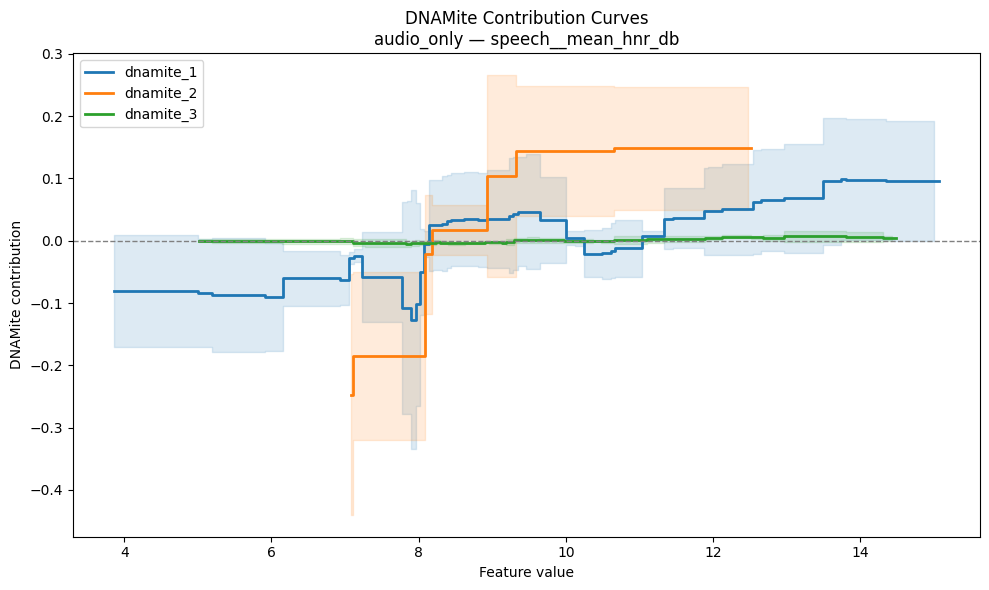

Saved: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/top_feature_analysis/dnamite_shape_plots/audio_only_speech__mean_hnr_db_dnamite_shape.png


In [47]:
plot_dnamite_shape(
    feature_set="audio_only",
    feature="speech__mean_hnr_db"
)

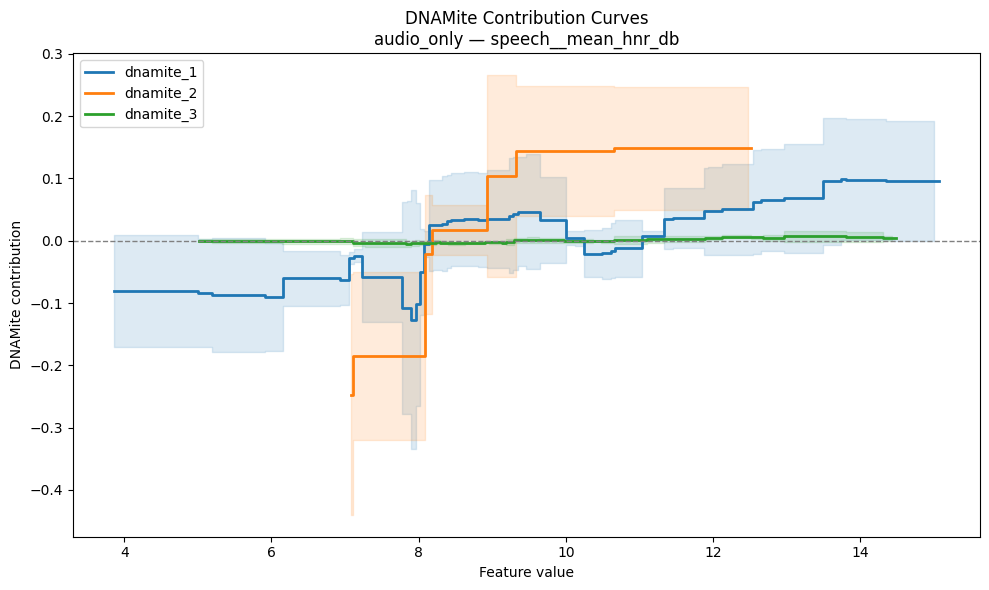

Saved: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/top_feature_analysis/dnamite_shape_plots/audio_only_speech__mean_hnr_db_dnamite_shape.png
dnamite_2: insufficient overlapping fold coverage for speech__spectral_std_dev


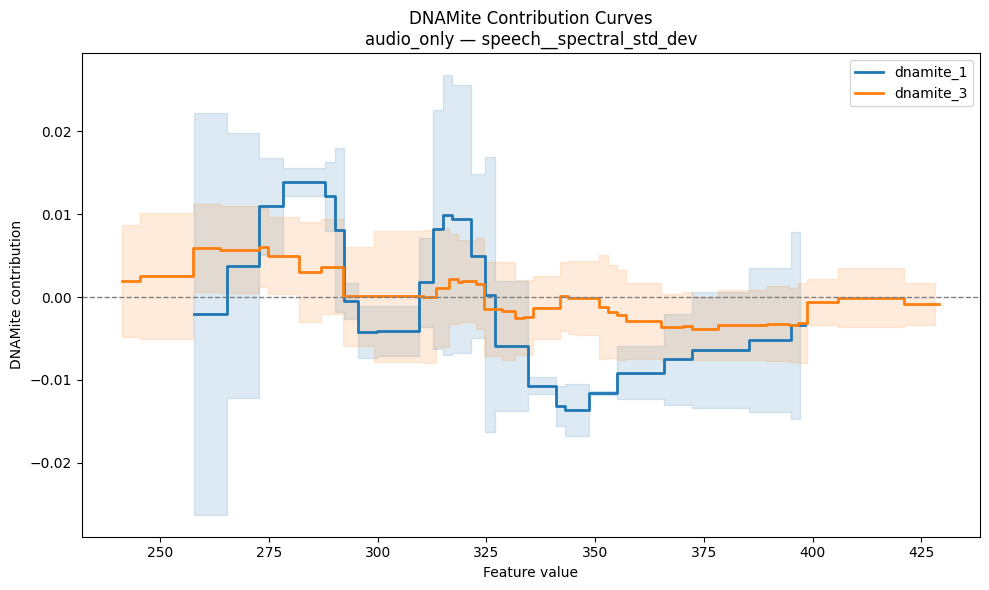

Saved: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/top_feature_analysis/dnamite_shape_plots/audio_only_speech__spectral_std_dev_dnamite_shape.png


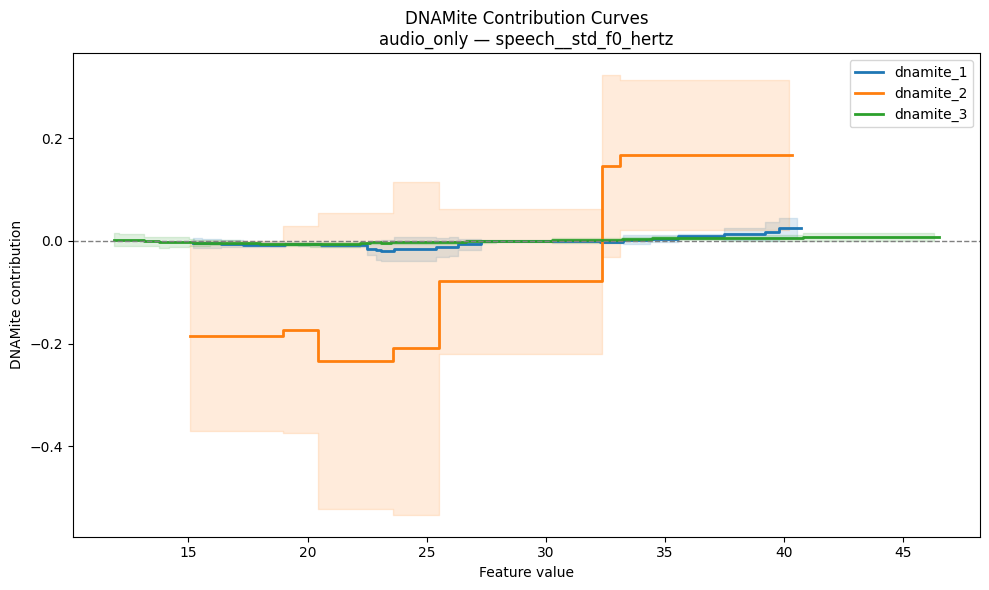

Saved: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/top_feature_analysis/dnamite_shape_plots/audio_only_speech__std_f0_hertz_dnamite_shape.png
dnamite_3: insufficient overlapping fold coverage for speech__std_f1_loc


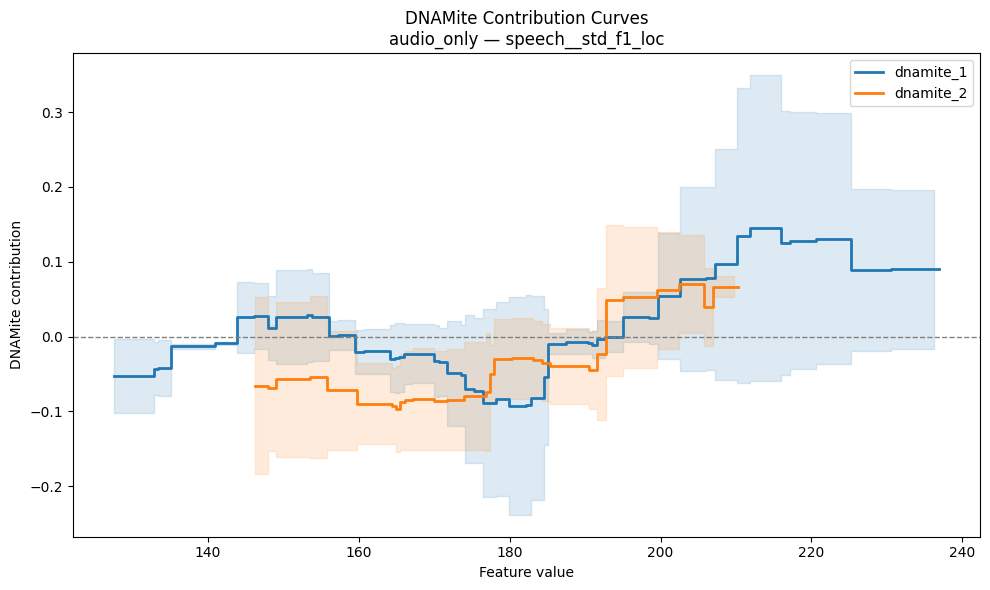

Saved: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/top_feature_analysis/dnamite_shape_plots/audio_only_speech__std_f1_loc_dnamite_shape.png


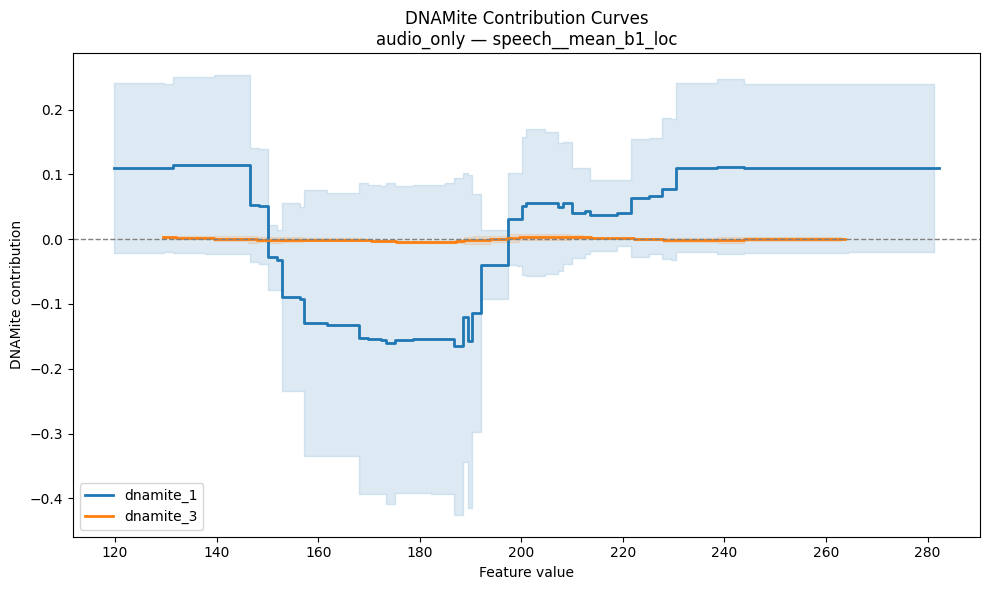

Saved: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/top_feature_analysis/dnamite_shape_plots/audio_only_speech__mean_b1_loc_dnamite_shape.png
dnamite_2: insufficient overlapping fold coverage for speech__mean_f2_loc


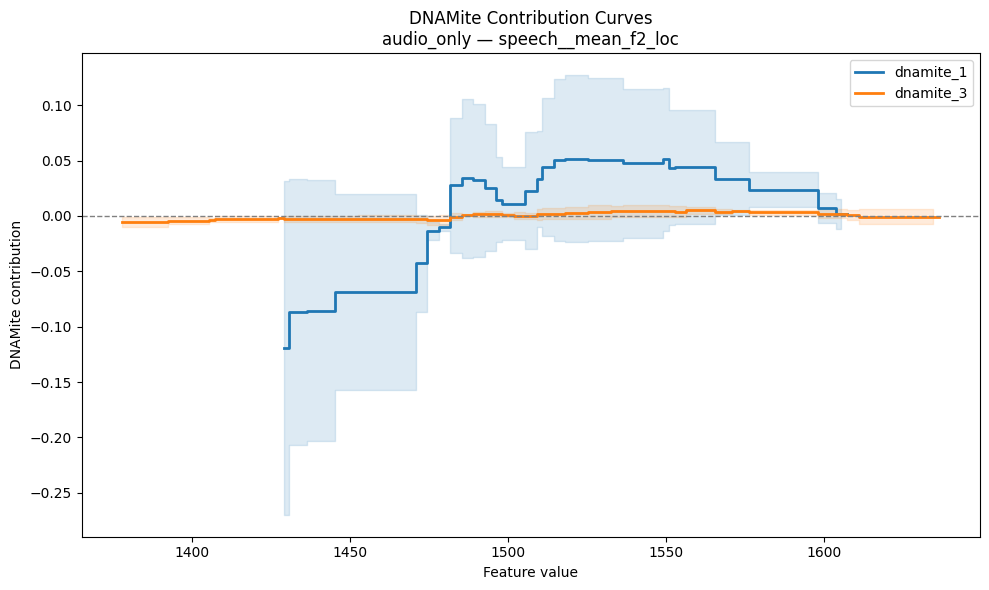

Saved: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/top_feature_analysis/dnamite_shape_plots/audio_only_speech__mean_f2_loc_dnamite_shape.png
dnamite_3: insufficient overlapping fold coverage for speech__std_f2_loc


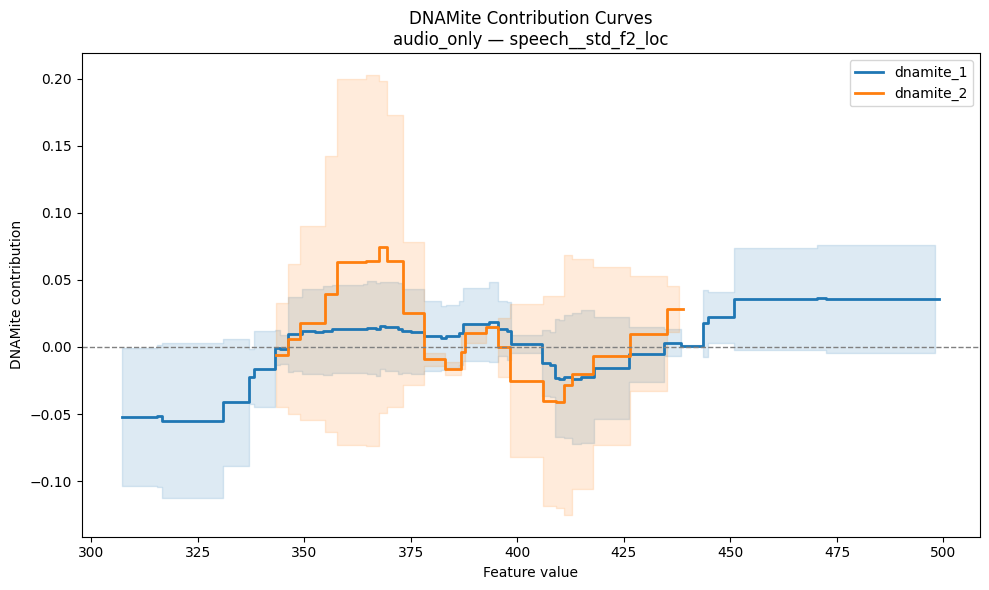

Saved: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/top_feature_analysis/dnamite_shape_plots/audio_only_speech__std_f2_loc_dnamite_shape.png


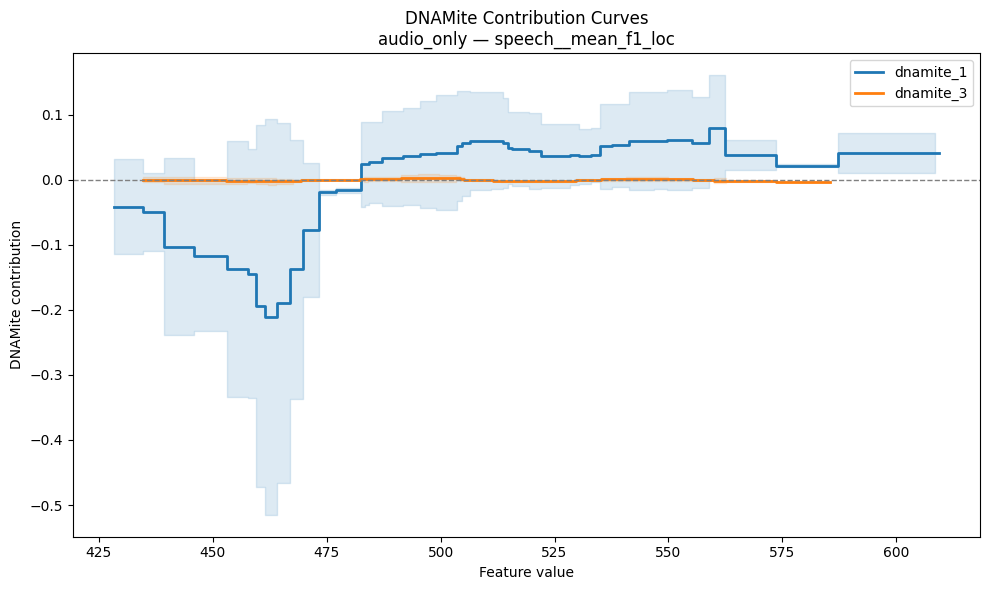

Saved: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/top_feature_analysis/dnamite_shape_plots/audio_only_speech__mean_f1_loc_dnamite_shape.png


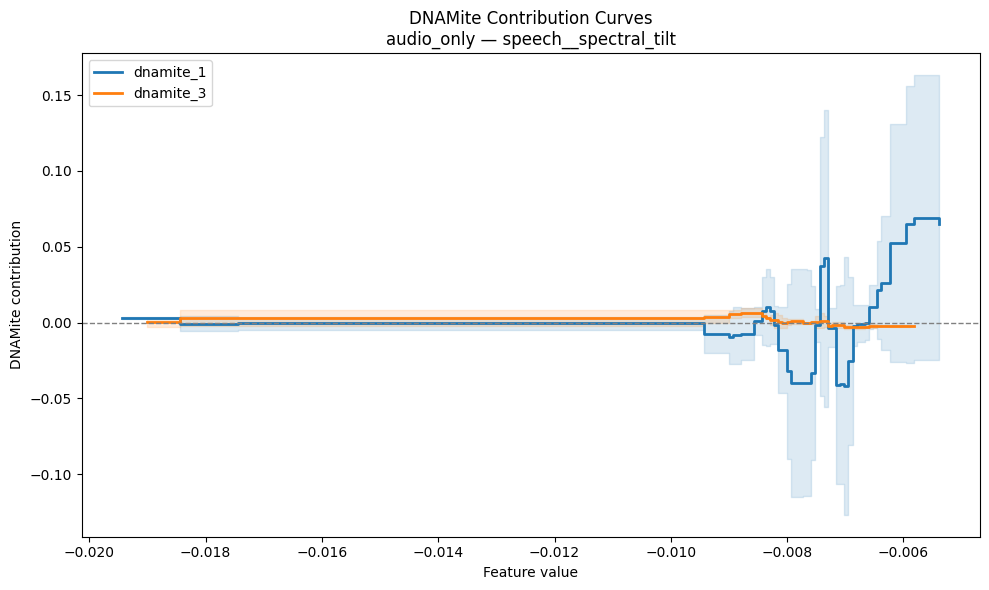

Saved: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/top_feature_analysis/dnamite_shape_plots/audio_only_speech__spectral_tilt_dnamite_shape.png


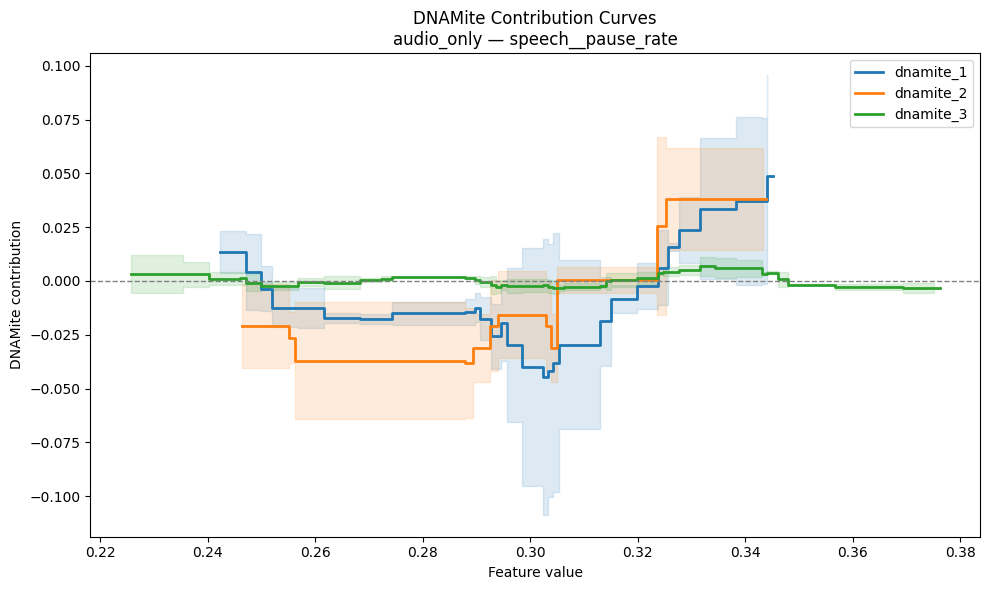

Saved: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/top_feature_analysis/dnamite_shape_plots/audio_only_speech__pause_rate_dnamite_shape.png


In [48]:
feature_set = "audio_only"

for feature in top_features[feature_set]["feature"].head(10):
    plot_dnamite_shape(feature_set, feature)

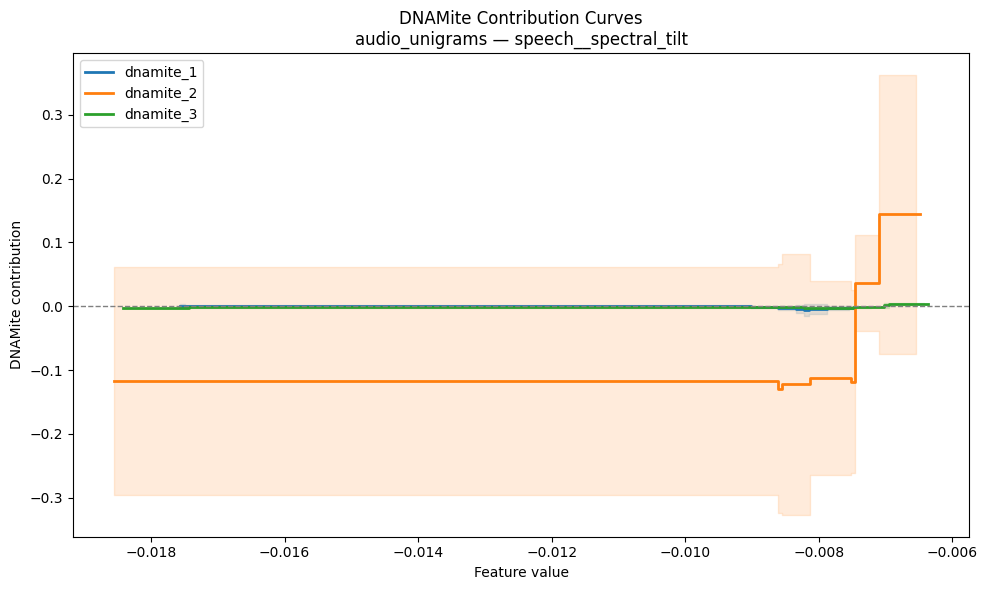

Saved: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/top_feature_analysis/dnamite_shape_plots/audio_unigrams_speech__spectral_tilt_dnamite_shape.png
dnamite_1: insufficient overlapping fold coverage for speech__std_f1_loc


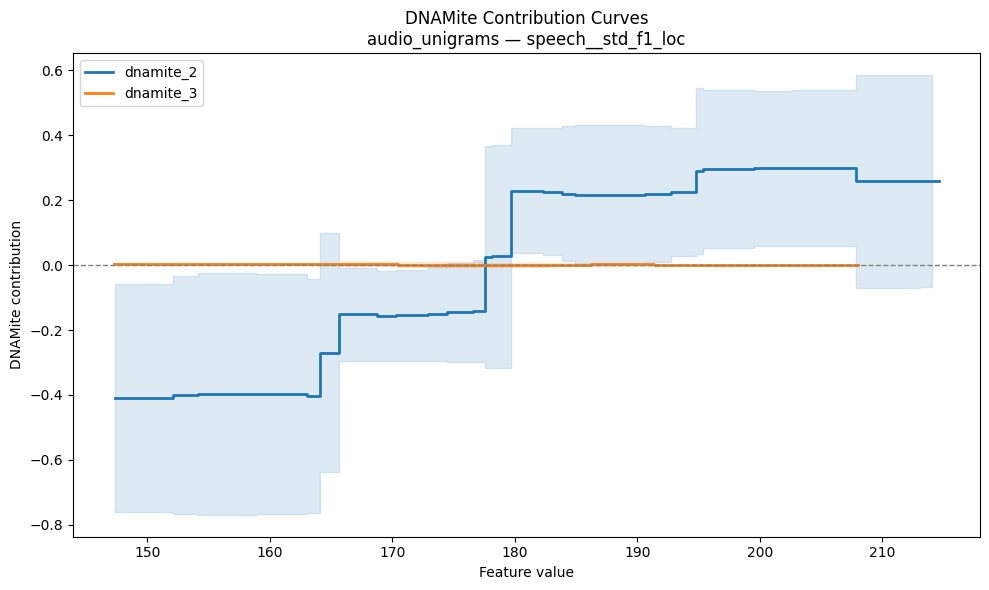

Saved: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/top_feature_analysis/dnamite_shape_plots/audio_unigrams_speech__std_f1_loc_dnamite_shape.png
dnamite_1: insufficient overlapping fold coverage for speech__mean_f0_hertz
dnamite_2: insufficient overlapping fold coverage for speech__mean_f0_hertz
dnamite_3: insufficient overlapping fold coverage for speech__mean_f0_hertz
No plottable overlapping curves for speech__mean_f0_hertz
dnamite_1: insufficient overlapping fold coverage for speech__mean_f2_loc
dnamite_3: insufficient overlapping fold coverage for speech__mean_f2_loc


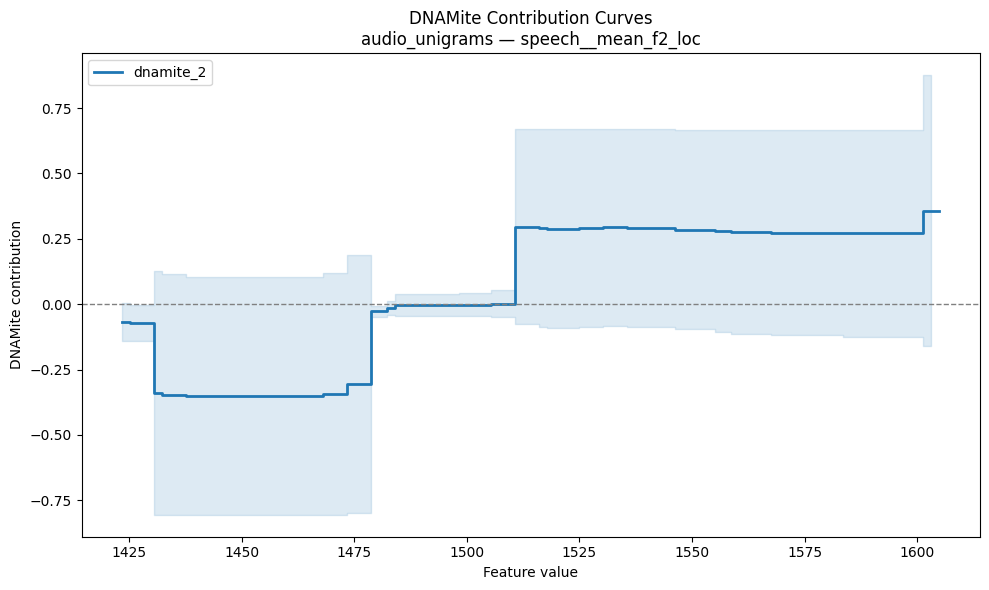

Saved: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/top_feature_analysis/dnamite_shape_plots/audio_unigrams_speech__mean_f2_loc_dnamite_shape.png


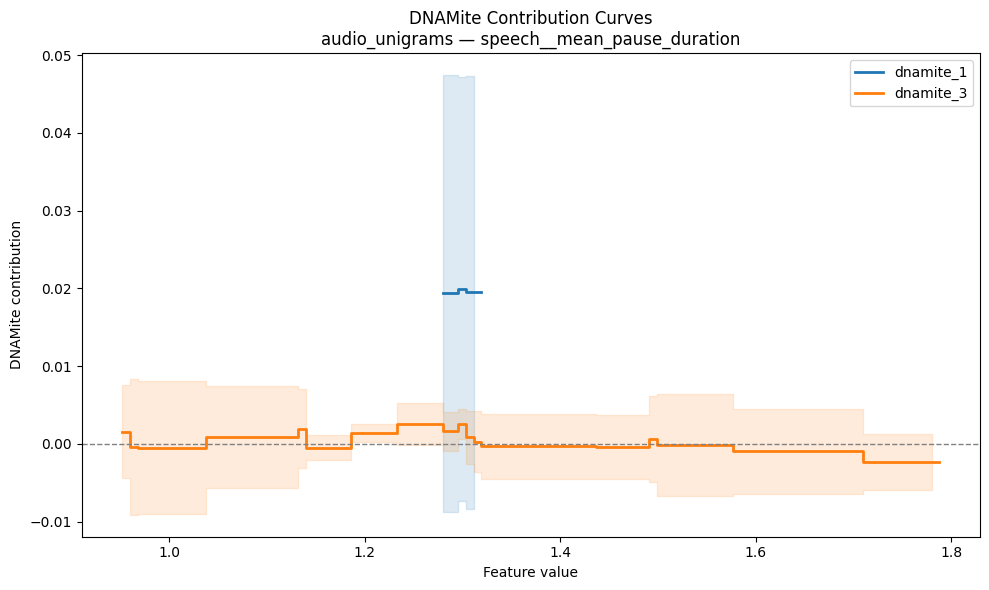

Saved: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/top_feature_analysis/dnamite_shape_plots/audio_unigrams_speech__mean_pause_duration_dnamite_shape.png
dnamite_1: insufficient overlapping fold coverage for speech__std_b1_loc
dnamite_3: insufficient overlapping fold coverage for speech__std_b1_loc


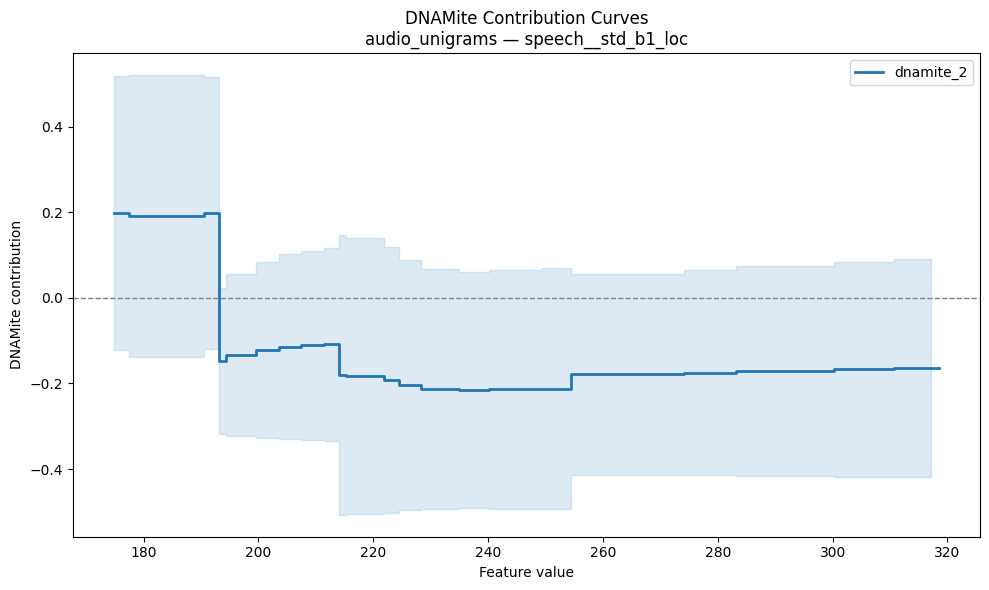

Saved: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/top_feature_analysis/dnamite_shape_plots/audio_unigrams_speech__std_b1_loc_dnamite_shape.png
dnamite_1: insufficient overlapping fold coverage for speech__mean_b1_loc
dnamite_3: insufficient overlapping fold coverage for speech__mean_b1_loc


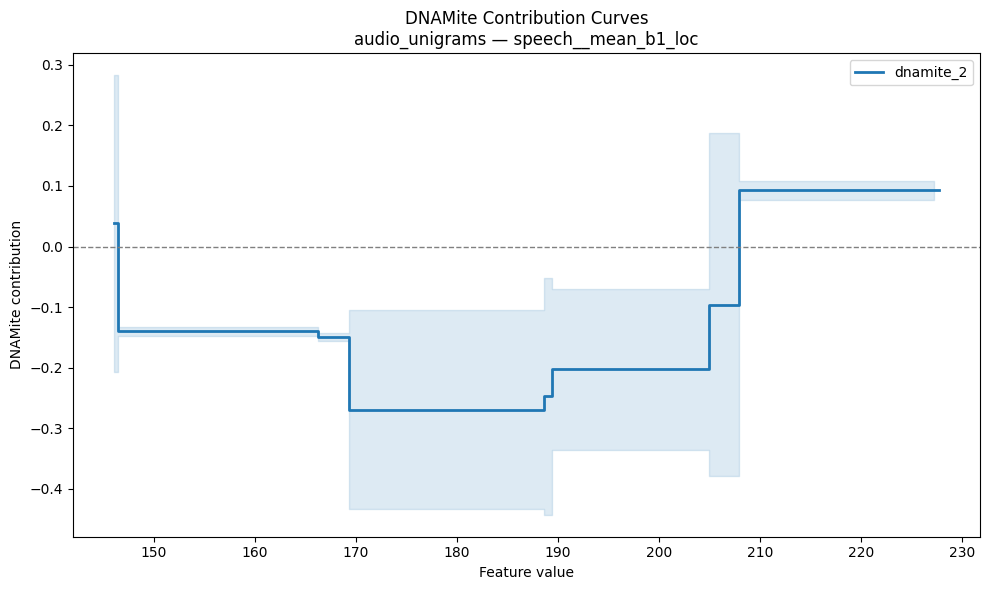

Saved: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/top_feature_analysis/dnamite_shape_plots/audio_unigrams_speech__mean_b1_loc_dnamite_shape.png


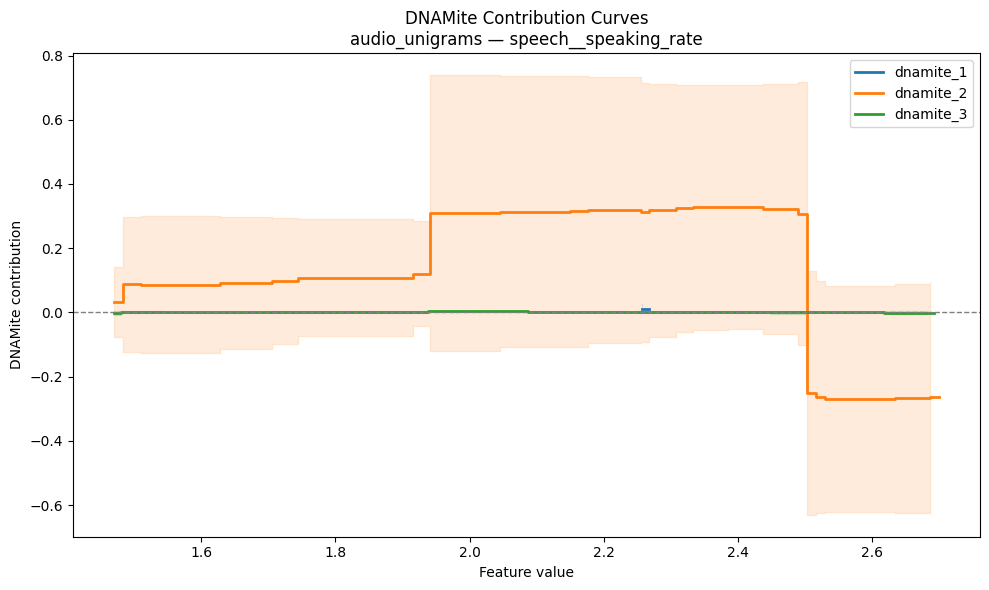

Saved: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/top_feature_analysis/dnamite_shape_plots/audio_unigrams_speech__speaking_rate_dnamite_shape.png


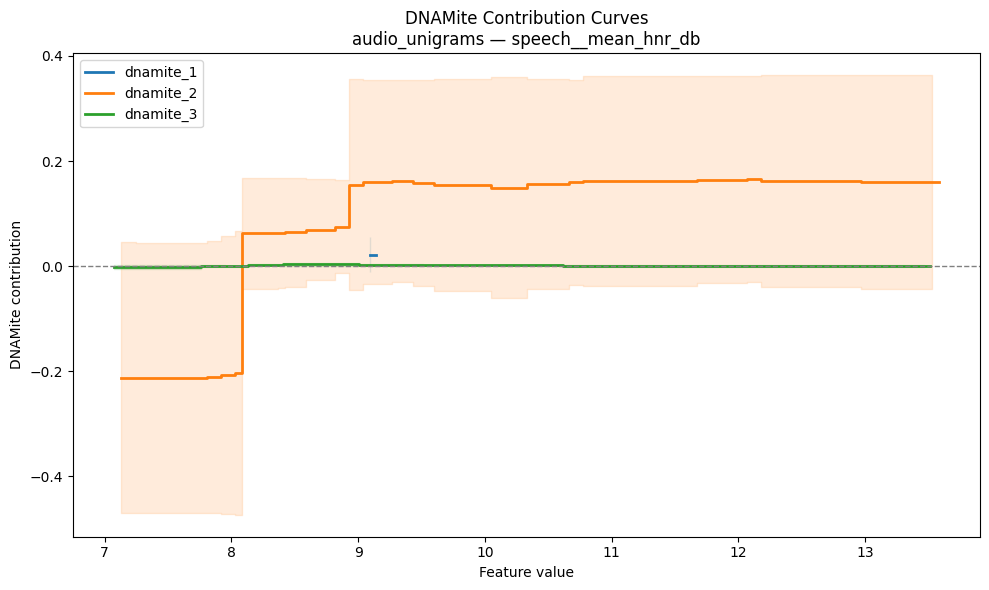

Saved: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/top_feature_analysis/dnamite_shape_plots/audio_unigrams_speech__mean_hnr_db_dnamite_shape.png


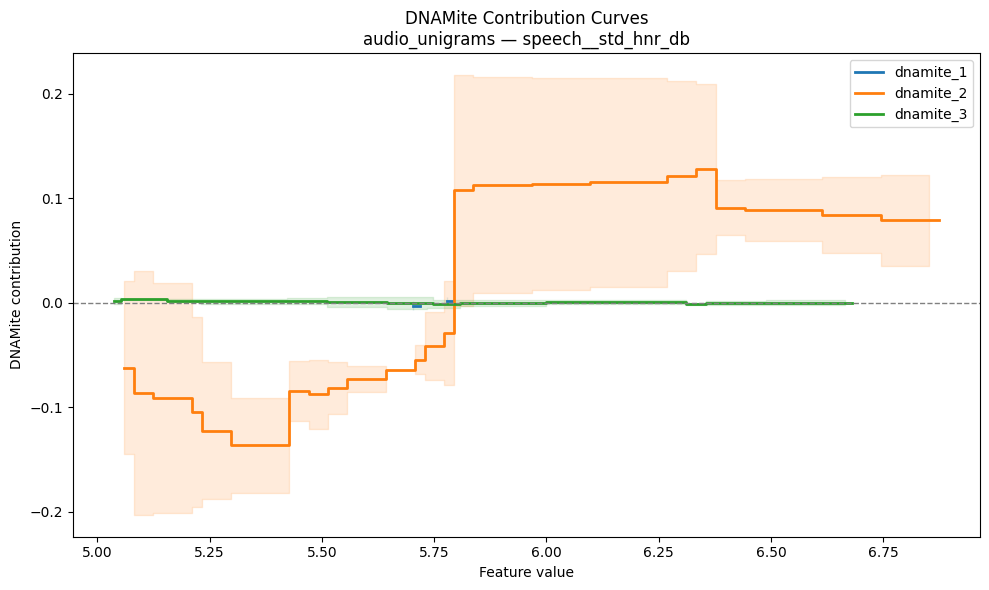

Saved: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/top_feature_analysis/dnamite_shape_plots/audio_unigrams_speech__std_hnr_db_dnamite_shape.png


In [49]:
for feature_set in [
    "audio_unigrams"
]:
    for feature in top_features[feature_set]["feature"].head(10):
        plot_dnamite_shape(feature_set, feature)

dnamite_2: insufficient overlapping fold coverage for text__a lot


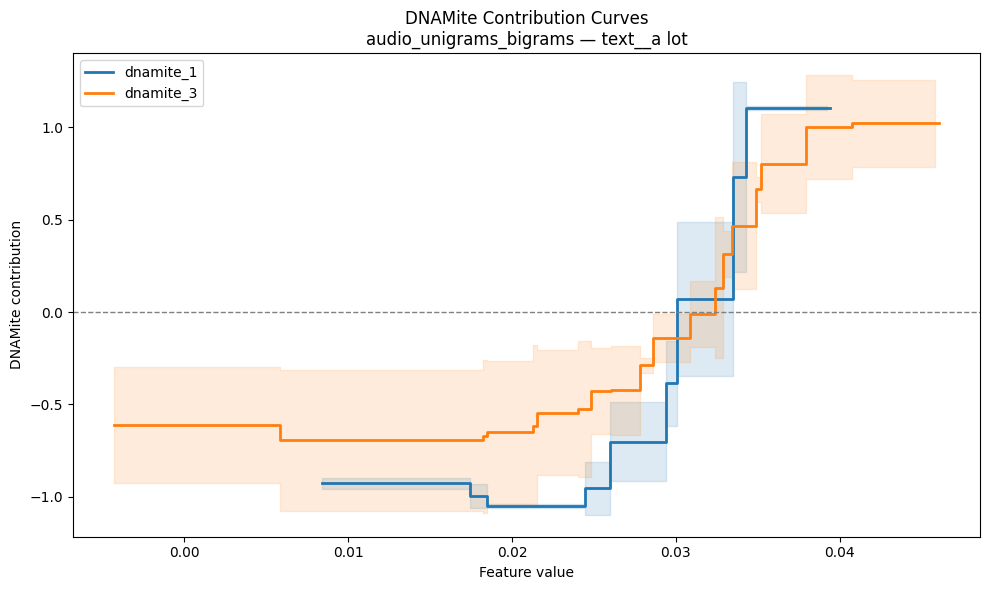

Saved: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/top_feature_analysis/dnamite_shape_plots/audio_unigrams_bigrams_text__a_lot_dnamite_shape.png


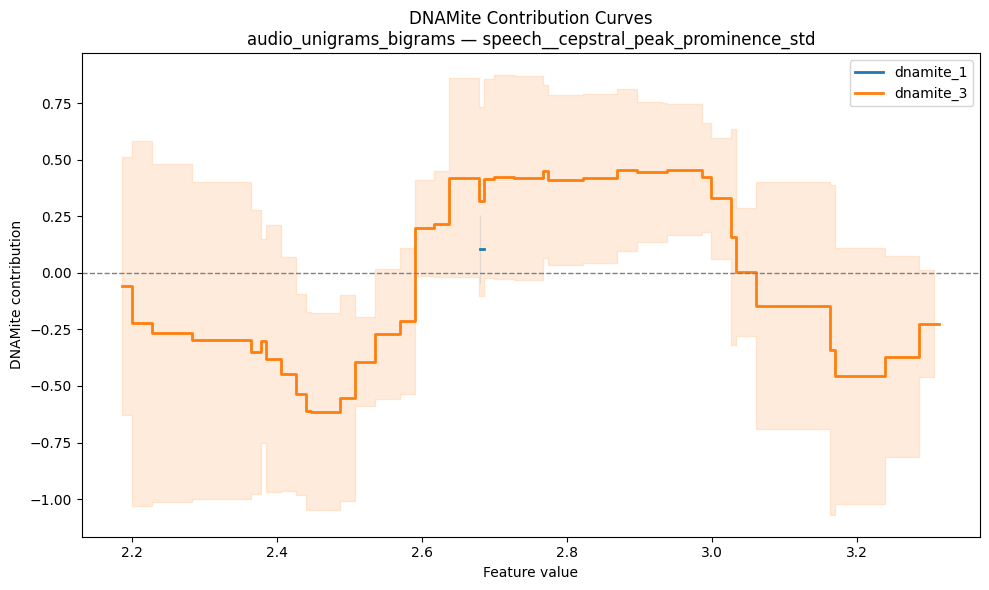

Saved: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/top_feature_analysis/dnamite_shape_plots/audio_unigrams_bigrams_speech__cepstral_peak_prominence_std_dnamite_shape.png
dnamite_1: insufficient overlapping fold coverage for speech__std_f2_loc
dnamite_2: insufficient overlapping fold coverage for speech__std_f2_loc


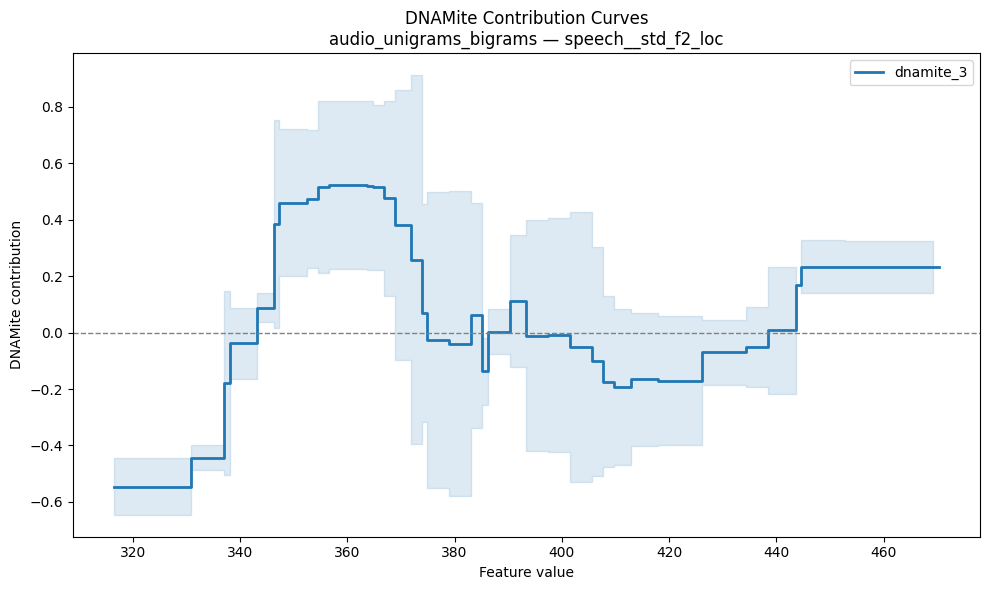

Saved: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/top_feature_analysis/dnamite_shape_plots/audio_unigrams_bigrams_speech__std_f2_loc_dnamite_shape.png
dnamite_2: insufficient overlapping fold coverage for speech__mean_b2_loc
dnamite_3: insufficient overlapping fold coverage for speech__mean_b2_loc
No plottable overlapping curves for speech__mean_b2_loc
dnamite_2: insufficient overlapping fold coverage for speech__spectral_slope
No plottable overlapping curves for speech__spectral_slope


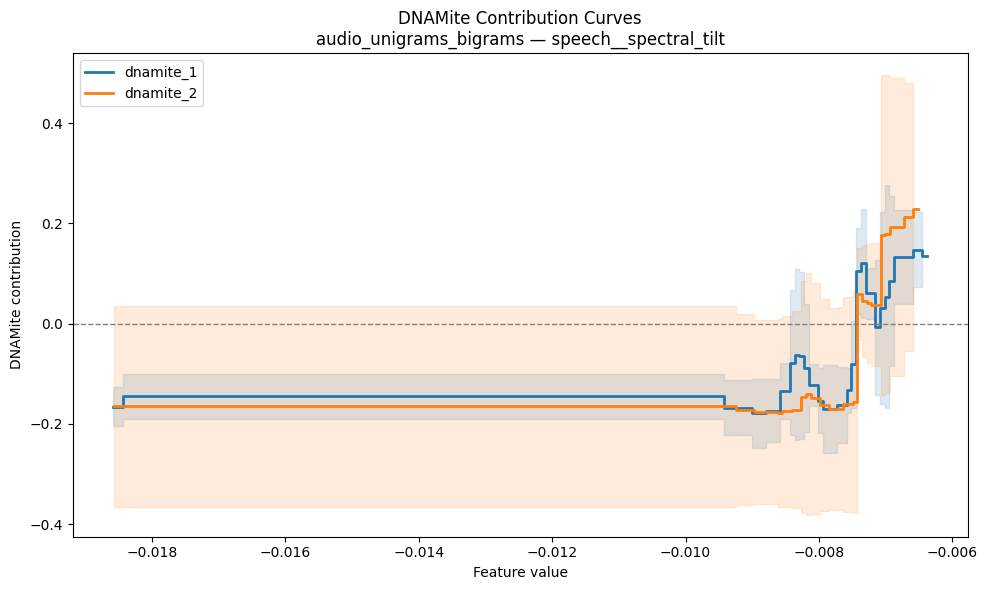

Saved: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/top_feature_analysis/dnamite_shape_plots/audio_unigrams_bigrams_speech__spectral_tilt_dnamite_shape.png
dnamite_1: insufficient overlapping fold coverage for speech__mean_b1_loc
dnamite_2: insufficient overlapping fold coverage for speech__mean_b1_loc
dnamite_3: insufficient overlapping fold coverage for speech__mean_b1_loc
No plottable overlapping curves for speech__mean_b1_loc


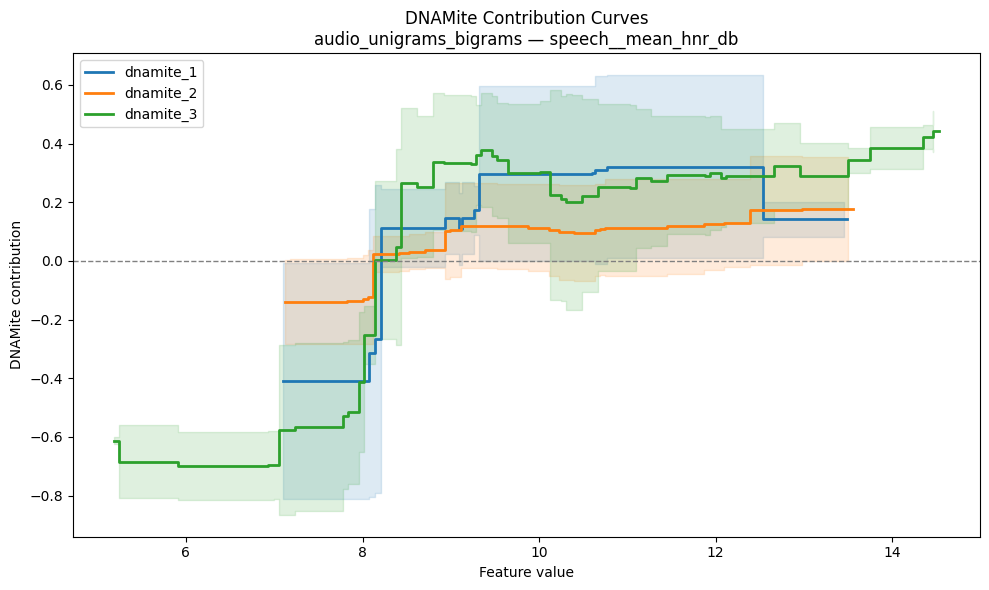

Saved: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/top_feature_analysis/dnamite_shape_plots/audio_unigrams_bigrams_speech__mean_hnr_db_dnamite_shape.png
dnamite_1: insufficient overlapping fold coverage for speech__mean_f2_loc
dnamite_2: insufficient overlapping fold coverage for speech__mean_f2_loc


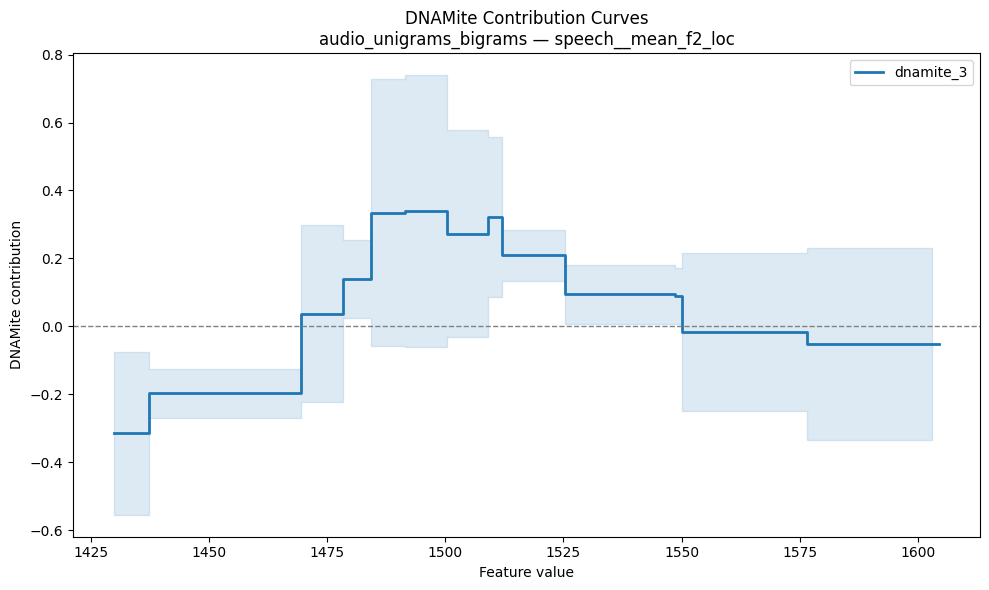

Saved: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/top_feature_analysis/dnamite_shape_plots/audio_unigrams_bigrams_speech__mean_f2_loc_dnamite_shape.png
dnamite_2: insufficient overlapping fold coverage for speech__range_ratio_intensity_db


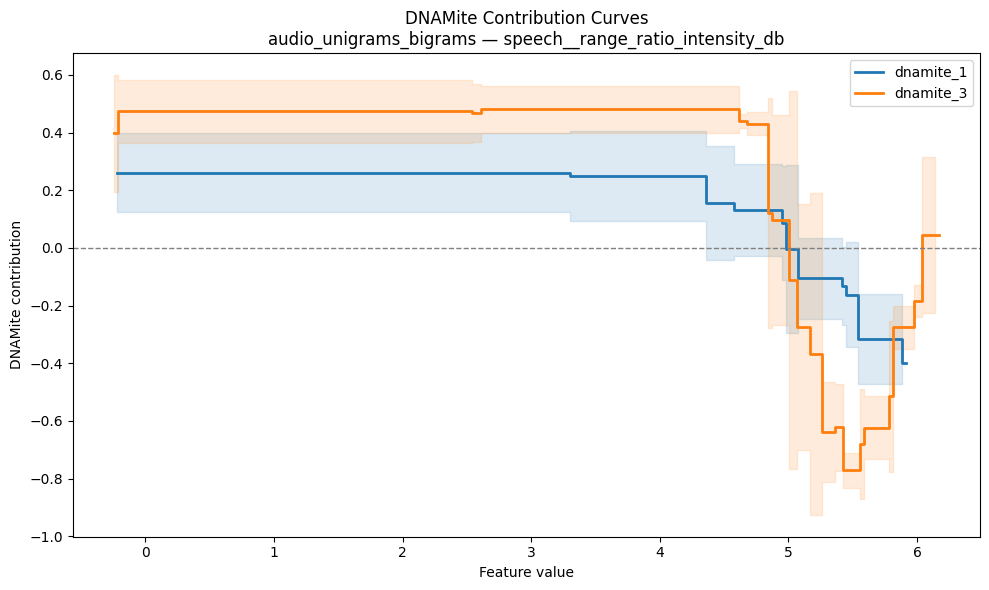

Saved: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/top_feature_analysis/dnamite_shape_plots/audio_unigrams_bigrams_speech__range_ratio_intensity_db_dnamite_shape.png


In [50]:
for feature_set in [
    "audio_unigrams_bigrams"
]:
    for feature in top_features[feature_set]["feature"].head(10):
        plot_dnamite_shape(feature_set, feature)

In [51]:
def inspect_dnamite_curve_coverage(feature_set, feature):

    df = dnamite_shape_curves[feature_set]
    df = df[df["feature"] == feature]

    if df.empty:
        print("Feature not found.")
        return

    summary = (
        df.groupby(["experiment", "fold"])
        .agg(
            n_points=("feature_value", "nunique"),
            min_value=("feature_value", "min"),
            max_value=("feature_value", "max"),
        )
        .reset_index()
    )

    print(summary.to_string(index=False))


inspect_dnamite_curve_coverage(
    "audio_only",
    "speech__mean_hnr_db"
)

experiment  fold  n_points  min_value  max_value
 dnamite_1     1        30   3.500359  15.489467
 dnamite_1     2         6   7.029474  13.472971
 dnamite_1     3         6   7.079129  12.506877
 dnamite_1     4         2   8.902169   8.912169
 dnamite_1     5        30   3.834925  15.045313
 dnamite_2     3         6   7.079129  12.506877
 dnamite_2     4         6   7.079129  13.550102
 dnamite_3     1        14   4.962978  14.439934
 dnamite_3     3         6   7.079129  12.506877
 dnamite_3     4         2   8.902169   8.912169
 dnamite_3     5        30   3.834925  15.045313
